In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from umap import UMAP

import torch
import torch.nn as nn
import torch.nn.functional as F
import pyliger

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/home/sc5625/.local/share/m

## Define helper functions

In [2]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref = top_support_mask(A_ref, frac=frac)
    tp = np.logical_and(pred, ref).sum()
    fp = pred.sum() - tp
    fn = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    jac = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "jaccard": float(jac),
        "tp": int(tp),
        "pred_edges": int(pred.sum()),
        "ref_edges": int(ref.sum()),
    }

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:  # per TF column
        for j in range(A_ref.shape[1]):
            p = top_support_mask(A_pred[:, j], frac=frac)
            r = top_support_mask(A_ref[:, j], frac=frac)
            scores.append(jaccard(p, r))
    else:  # per gene row
        for i in range(A_ref.shape[0]):
            p = top_support_mask(A_pred[i, :], frac=frac)
            r = top_support_mask(A_ref[i, :], frac=frac)
            scores.append(jaccard(p, r))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    # W: genes x r, H: r x tfs
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules] for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {
        "mean_conservation": float(np.mean(matched)),
        "std_conservation": float(np.std(matched)),
        "matched_scores": matched,
        "similarity_matrix": S,
    }

def pseudotime_arrow_agreement(X_space, V_pred, pseudotime, k=30):
    """
    For each cell, find the nearest neighbor with slightly larger pseudotime
    among local neighbors, and compare that arrow with predicted velocity.
    Returns mean cosine agreement and fraction positive.
    """
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_space))).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]

    arrows = np.zeros_like(X_space, dtype=float)
    valid = np.zeros(len(X_space), dtype=bool)

    for i in range(len(X_space)):
        nbrs = idx[i]
        later = nbrs[pseudotime[nbrs] > pseudotime[i]]
        if later.size == 0:
            continue
        j = later[np.argmin(pseudotime[later] - pseudotime[i])]
        arrows[i] = X_space[j] - X_space[i]
        valid[i] = True

    if valid.sum() == 0:
        return {"mean_cosine": np.nan, "fraction_positive": np.nan, "n_valid": 0}

    Vn = normalize(V_pred[valid], norm="l2", axis=1)
    An = normalize(arrows[valid], norm="l2", axis=1)
    cos = np.sum(Vn * An, axis=1)

    return {
        "mean_cosine": float(np.mean(cos)),
        "fraction_positive": float(np.mean(cos > 0)),
        "n_valid": int(valid.sum()),
        "cosines": cos,
    }

## Step 1: Load RNA and define model universe (genes, TFs)

In [3]:
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
os.makedirs("uv_leading_metrics_improved", exist_ok=True)

rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

X = X_full[:, gene_idx]      # cells x genes
X_TF = X_full[:, tf_idx]     # cells x TFs
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


## Step 2: Build M (gene x TF accessibility mask)

In [4]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to the TFs actually present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]  # refresh after final TF filtering
M = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))

## Step 3: ATAC gene activity and gene accessibility prior

In [5]:
# ============================================================
# STEP 3 (REPLACE): ATAC gene activity and gene accessibility
# ============================================================

print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # cells x peaks

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

# IMPORTANT: do NOT row-align unpaired ATAC to RNA unless the data are truly paired.
# Use all ATAC cells for global priors and latent geometry.
gene_access = gene_activity.mean(axis=0)
gene_access = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

print(f"ATAC gene_activity shape: {gene_activity.shape}")
print(f"gene_access shape: {gene_access.shape}")

Loading ATAC raw matrix...
ATAC gene_activity shape: (18489, 11483)
gene_access shape: (11483,)


## Step 4: Joint space via LIGER

In [6]:
# ============================================================
# NEW STEP 4: Decipher-Constrained Future Projection
# ============================================================
from sklearn.neighbors import NearestNeighbors
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
import numpy as np
import torch

# Ensure we have the device and tensors ready
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_t = torch.tensor(X, dtype=torch.float32, device=device)

# --------------------------------------------------
# 1. Build per-ATAC-cell TF accessibility score
# --------------------------------------------------
print("Step 4.1: Computing per-ATAC-cell TF accessibility...")

# Align Step 3 ATAC peaks to Step 1 Motif peaks
# Step 1 peaks used '-', Step 3 peak_names used ':'
# We map them to ensure we subset peak_tf correctly
peak_to_idx_motif = {p: i for i, p in enumerate(peaks)} 
valid_atac_indices = []
valid_motif_indices = []

for j, p_atac in enumerate(peak_names):
    # Reverse the 'fix_peak' logic to match Step 1 format
    p_orig = p_atac.replace(":", "-", 1)
    if p_orig in peak_to_idx_motif:
        valid_atac_indices.append(j)
        valid_motif_indices.append(peak_to_idx_motif[p_orig])

# subset matrices for TF activity calculation
# peak_tf is (Peaks_Total x TFs_Total), tf_col selects TFs present in RNA
atac_X_sub = atac_X[:, np.array(valid_atac_indices)]
peak_tf_sub = peak_tf[np.array(valid_motif_indices)][:, tf_col]

# Cells x TFs
TF_access_atac = as_dense(atac_X_sub @ peak_tf_sub).astype(np.float32)
TF_access_atac = np.log1p(TF_access_atac / (TF_access_atac.sum(axis=1, keepdims=True) + 1e-8) * 1e4)

# --------------------------------------------------
# 2. Transfer ATAC TF scores to RNA cells
# --------------------------------------------------
print("Step 4.2: Transferring ATAC to RNA using Decipher-guided kNN...")

# Reuse gene_activity from Step 3 (already log-normalized cells x genes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
atac_scaled = scaler.transform(gene_activity)

# kNN Transfer
k_transfer = 20
nn_transfer = NearestNeighbors(n_neighbors=k_transfer, metric='cosine', n_jobs=-1).fit(atac_scaled)
dists, indices = nn_transfer.kneighbors(X_scaled)

# Weights
sigmas = np.median(dists, axis=1, keepdims=True) + 1e-8
weights = np.exp(-(dists**2) / (2 * sigmas**2))
weights /= (weights.sum(axis=1, keepdims=True) + 1e-8)

# Transfer TF accessibility to RNA cells: (N, k) * (N, k, TFs) -> (N, TFs)
TF_access_rna = np.sum(weights[:, :, np.newaxis] * TF_access_atac[indices], axis=1)

Step 4.1: Computing per-ATAC-cell TF accessibility...
Step 4.2: Transferring ATAC to RNA using Decipher-guided kNN...


Global sign check (positive = correct): 0.0447
Sign is correct


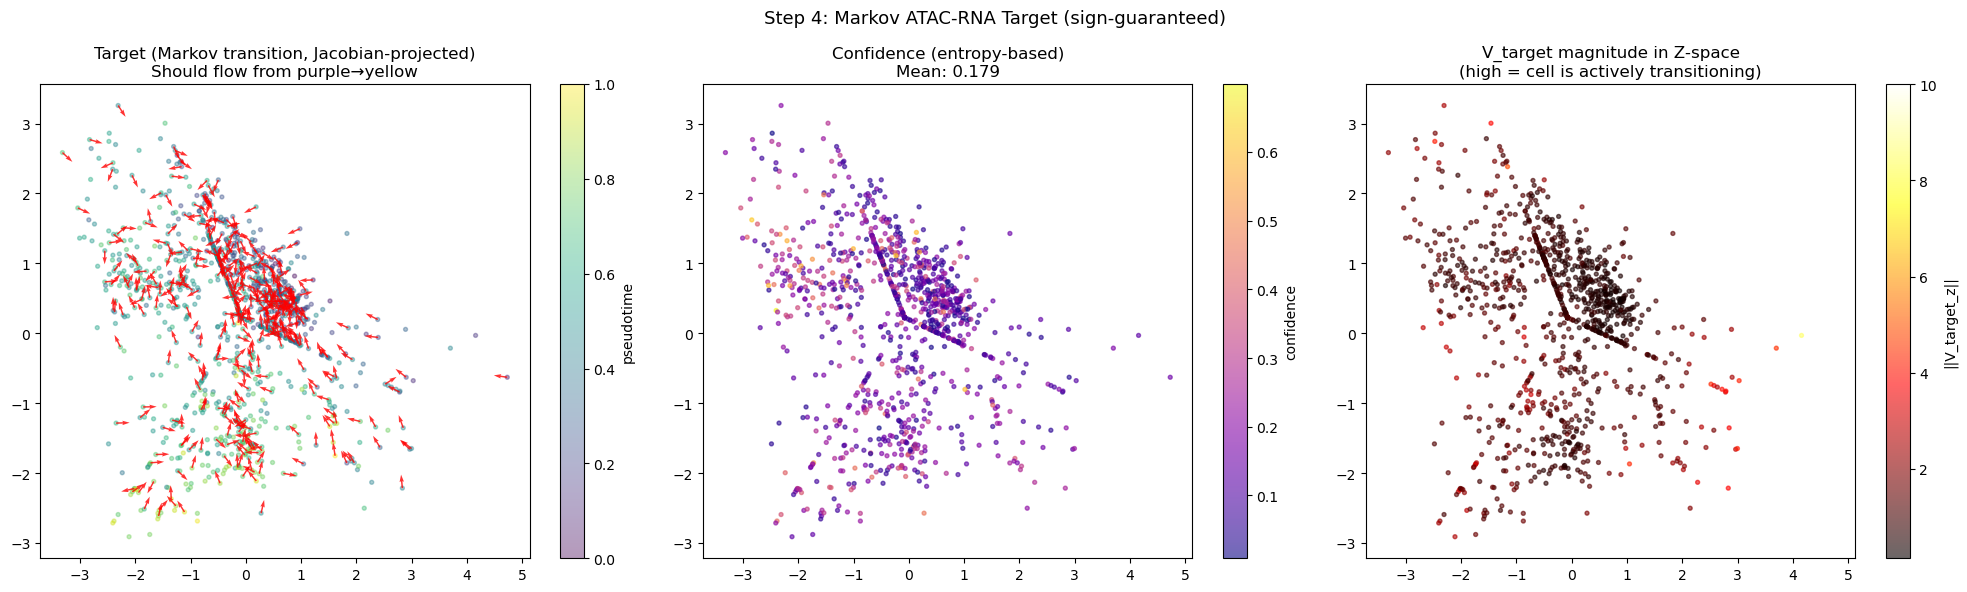

Mean confidence:           0.179
High-conf cells (>0.5):    1.5%
Mean V_target_z magnitude: 1.0281


In [29]:
# ============================================================
# STEP 4 (FINAL): Markov transition matrix velocity target
#
# Core idea from RNA velocity literature (La Manno / Bergen):
# Instead of computing a direction vector directly (which has sign
# ambiguity), compute a TRANSITION PROBABILITY from each cell to
# each neighbor, then the expected displacement IS the velocity.
#
# Here we use ATAC-RNA discrepancy to score transitions, but the
# Markov framing guarantees arrows point toward cells that look
# more like the ATAC-primed future state — no sign ambiguity.
#
# Requires: Z_dec, V_vis, X (RNA), X_TF, TF_access_rna, M
# ============================================================
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
Z_dec = decipher_data["z"].astype(np.float32)   # (N, 10)
V_vis = decipher_data["v"].astype(np.float32)   # (N, 2)
N     = Z_dec.shape[0]
ps    = rna_adata.obs["facs_pseudotime"].values.astype(np.float32)

# ── 4A. ATAC-predicted future expression ─────────────────────────────────
# TF_access_rna @ M.T gives ATAC-primed gene expression: what does chromatin
# say each cell WILL express? This is the "future" RNA state.
X_atac_pred = TF_access_rna @ M.T               # (N, G) raw ATAC prediction

# Z-score each on its own axis so scales match
X_rna_z  = zscore(X,           axis=0).astype(np.float32)   # (N, G)
X_atac_z = zscore(X_atac_pred, axis=0).astype(np.float32)   # (N, G)

# Per-cell discrepancy: what does ATAC say this cell should move toward?
# This is the "ideal future expression" minus current expression
V_gene_raw  = X_atac_z - X_rna_z                # (N, G)

# ── 4B. Global sign correction BEFORE building the transition matrix ──────
# Use the linear pseudotime gradient in Z-space as a reference direction.
# We only use pseudotime here for a one-time global sign check — not as
# supervision. If the ATAC signal globally opposes pseudotime, flip it.
reg_ps       = LinearRegression().fit(Z_dec, ps)
ps_gradient  = reg_ps.coef_.astype(np.float32)  # (Z_dim,) direction of increasing ps in Z
ps_gradient /= (np.linalg.norm(ps_gradient) + 1e-8)

# Project each cell's gene-space discrepancy onto Z via the Jacobian
# We need a G → Z map: use Ridge regression from X_rna_z → Z_dec
from sklearn.linear_model import Ridge
reg_gene2z = Ridge(alpha=10.0).fit(X_rna_z, Z_dec)
J_gene2z   = reg_gene2z.coef_.astype(np.float32)  # (Z_dim, G)

# Project discrepancy into Z-space to check sign
V_gene_in_z = (J_gene2z @ V_gene_raw.T).T         # (N, Z_dim)
V_gene_in_z_norm = V_gene_in_z / (np.linalg.norm(V_gene_in_z, axis=1, keepdims=True) + 1e-8)

global_sign = (V_gene_in_z_norm @ ps_gradient).mean()
print(f"Global sign check (positive = correct): {global_sign:.4f}")

if global_sign < 0:
    print("Flipping ATAC discrepancy sign")
    V_gene_raw = -V_gene_raw
else:
    print("Sign is correct")

V_gene_norm = V_gene_raw / (np.linalg.norm(V_gene_raw, axis=1, keepdims=True) + 1e-8)

# ── 4C. Build kNN graph in Z-space ───────────────────────────────────────
k_nn = 30
nn_z = NearestNeighbors(n_neighbors=k_nn + 1, metric='euclidean').fit(Z_dec)
dists_z, idx_z = nn_z.kneighbors(Z_dec)
idx_z   = idx_z[:, 1:]    # (N, k_nn)
dists_z = dists_z[:, 1:]

# ── 4D. Transition probability matrix (the key fix) ───────────────────────
# For cell i, transition probability to neighbor j:
#   p(i→j) ∝ exp( alignment(j's RNA - i's RNA, i's ATAC target) / T )
# This is exactly the La Manno (2018) cosine kernel, adapted for ATAC.
#
# Critical: we score the DIRECTION of movement (i→j in RNA space)
# against what ATAC says the cell wants. High score = j is a valid future.

V_target_z  = np.zeros((N, Z_dec.shape[1]), dtype=np.float32)
conf_scores = np.zeros(N, dtype=np.float32)
T_softmax   = 0.05   # temperature: lower = sharper transitions

for i in range(N):
    nbrs      = idx_z[i]           # (k,)
    nbr_d     = dists_z[i]         # (k,)

    # RNA displacement from i to each neighbor (in gene space)
    delta_rna = X_rna_z[nbrs] - X_rna_z[i]    # (k, G)

    # Cosine similarity: does moving to neighbor j align with ATAC target?
    d_norm    = delta_rna / (np.linalg.norm(delta_rna, axis=1, keepdims=True) + 1e-8)
    cos_score = d_norm @ V_gene_norm[i]         # (k,) in [-1, 1]

    # Distance weight: prefer nearby cells
    dist_w    = np.exp(-nbr_d / (nbr_d.mean() + 1e-8))

    # Transition probability: softmax over (alignment + distance)
    # Temperature controls sharpness
    score     = cos_score / T_softmax + np.log(dist_w + 1e-8)
    score_exp = np.exp(score - score.max())     # numerically stable softmax
    p_trans   = score_exp / (score_exp.sum() + 1e-8)   # (k,) sums to 1

    # Expected Z-displacement under transition distribution
    z_disps   = Z_dec[nbrs] - Z_dec[i]         # (k, Z_dim)
    V_target_z[i] = p_trans @ z_disps           # (Z_dim,) — expected future displacement

    # Confidence: how peaked is the distribution? (entropy-based)
    # Uniform = 0 confidence, peaked = high confidence
    entropy   = -np.sum(p_trans * np.log(p_trans + 1e-8))
    max_entropy = np.log(k_nn)
    conf_scores[i] = 1.0 - entropy / max_entropy    # high conf = low entropy

# Normalize Z-target
V_target_z_norm = V_target_z / (np.linalg.norm(V_target_z, axis=1, keepdims=True) + 1e-8)

# ── 4E. Diagnostic: project to 2D using Jacobian (not cosine weighting) ──
reg_z2vis = Ridge(alpha=1.0).fit(Z_dec, V_vis)
J_z2vis   = reg_z2vis.coef_.astype(np.float32)    # (2, Z_dim)

V_target_2d = (J_z2vis @ V_target_z.T).T          # (N, 2)
V_target_2d /= (np.linalg.norm(V_target_2d, axis=1, keepdims=True) + 1e-8)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
samp = np.random.choice(N, 400, replace=False)

sc = axes[0].scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis', s=8, alpha=0.4)
axes[0].quiver(V_vis[samp, 0], V_vis[samp, 1],
               V_target_2d[samp, 0], V_target_2d[samp, 1],
               color='red', width=0.003, alpha=0.8)
axes[0].set_title("Target (Markov transition, Jacobian-projected)\nShould flow from purple→yellow")
plt.colorbar(sc, ax=axes[0], label='pseudotime')

sc2 = axes[1].scatter(V_vis[:, 0], V_vis[:, 1], c=conf_scores, cmap='plasma', s=8, alpha=0.6)
axes[1].set_title(f"Confidence (entropy-based)\nMean: {conf_scores.mean():.3f}")
plt.colorbar(sc2, ax=axes[1], label='confidence')

sc3 = axes[2].scatter(V_vis[:, 0], V_vis[:, 1],
                      c=np.linalg.norm(V_target_z, axis=1), cmap='hot', s=8, alpha=0.6)
axes[2].set_title("V_target magnitude in Z-space\n(high = cell is actively transitioning)")
plt.colorbar(sc3, ax=axes[2], label='||V_target_z||')

plt.suptitle("Step 4: Markov ATAC-RNA Target (sign-guaranteed)", fontsize=13)
plt.tight_layout()
plt.savefig("step4_markov_target.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"Mean confidence:           {conf_scores.mean():.3f}")
print(f"High-conf cells (>0.5):    {(conf_scores > 0.5).mean()*100:.1f}%")
print(f"Mean V_target_z magnitude: {np.linalg.norm(V_target_z, axis=1).mean():.4f}")

# ── Pass tensors forward ──────────────────────────────────────────────────
X_z_t        = torch.tensor(X_rna_z,         dtype=torch.float32, device=device)
X_TF_t       = torch.tensor(X_TF,            dtype=torch.float32, device=device)
Z_dec_t      = torch.tensor(Z_dec,           dtype=torch.float32, device=device)
V_target_z_t = torch.tensor(V_target_z_norm, dtype=torch.float32, device=device)
conf_t       = torch.tensor(conf_scores,      dtype=torch.float32, device=device)
nn_idx       = torch.tensor(idx_z,           dtype=torch.long,    device=device)

Target sanity check — ps correlation with arrow direction: 0.176 (should be > 0.3)


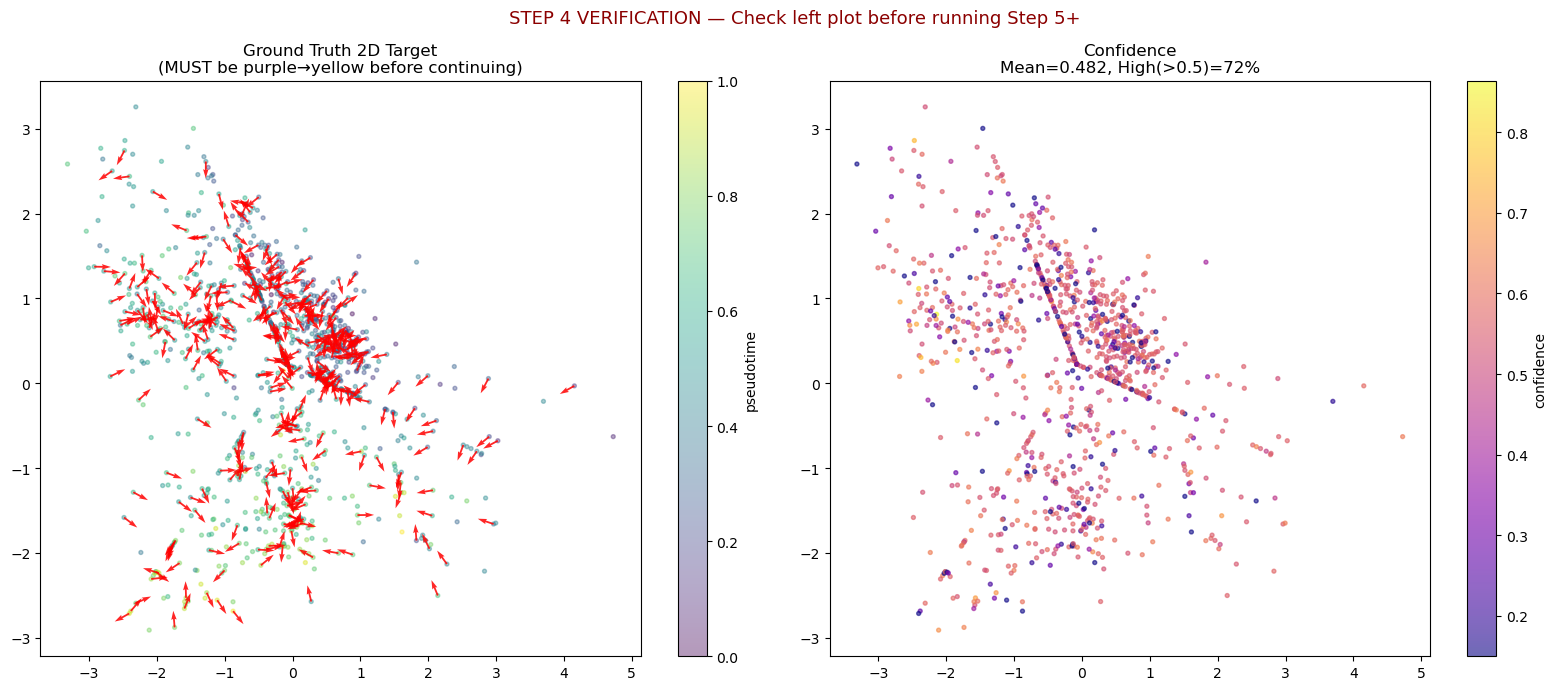

In [36]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from scipy.stats import zscore
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
Z_dec = decipher_data["z"].astype(np.float32)   # (N, 10)
V_vis = decipher_data["v"].astype(np.float32)   # (N, 2)
N     = Z_dec.shape[0]
ps    = rna_adata.obs["facs_pseudotime"].values.astype(np.float32)

# Normalize pseudotime to [0,1] just in case
ps = (ps - ps.min()) / (ps.max() - ps.min() + 1e-8)

X_rna_z  = zscore(X,    axis=0).astype(np.float32)   # (N, G)
X_TF_arr = X_TF.astype(np.float32)                    # (N, T)

# ============================================================
# STEP 4: Build ground-truth transition matrix in V_vis space
#
# Core idea: for each cell i, find neighbors in V_vis that have
# higher pseudotime. The TARGET 2D velocity = weighted average
# of (V_vis[j] - V_vis[i]) for future neighbors j.
# This is the scVelo RNA velocity idea but using pseudotime
# directly as the "splicing" signal, and V_vis as the space.
#
# We build a TRANSITION PROBABILITY MATRIX P (N x k) where
# P[i,j] = probability of transitioning from cell i to neighbor j.
# The expected 2D displacement = P[i,:] @ (V_vis[neighbors] - V_vis[i])
# ============================================================

# Build kNN in V_vis (2D) — this is the space we care about
k_vis = 20
nn_vis = NearestNeighbors(n_neighbors=k_vis + 1).fit(V_vis)
dists_vis, idx_vis = nn_vis.kneighbors(V_vis)
idx_vis   = idx_vis[:, 1:]    # (N, k_vis)
dists_vis = dists_vis[:, 1:]

# Also build kNN in Z (for model training / consistency loss)
k_nn = 20
nn_z = NearestNeighbors(n_neighbors=k_nn + 1, metric='euclidean').fit(Z_dec)
dists_z, idx_z = nn_z.kneighbors(Z_dec)
idx_z   = idx_z[:, 1:]
dists_z = dists_z[:, 1:]

# Compute ATAC-RNA discrepancy magnitude per cell (used as weight only)
X_atac_pred  = TF_access_rna @ M.T                   # (N, G)
X_atac_z     = zscore(X_atac_pred, axis=0).astype(np.float32)
atac_rna_mag = np.linalg.norm(X_atac_z - X_rna_z, axis=1)  # (N,)
atac_rna_mag = (atac_rna_mag - atac_rna_mag.min()) / (atac_rna_mag.max() - atac_rna_mag.min() + 1e-8)

# Build ground truth 2D velocity and transition weights
V_gt_2d     = np.zeros((N, 2), dtype=np.float32)
P_trans     = np.zeros((N, k_vis), dtype=np.float32)   # transition probs
conf_scores = np.zeros(N, dtype=np.float32)

PS_DELTA = 0.001   # minimum pseudotime advantage to count as "future"

for i in range(N):
    nbrs   = idx_vis[i]          # (k_vis,)
    d_vis  = dists_vis[i]        # (k_vis,)
    ps_nbr = ps[nbrs]

    # Forward neighbors: higher pseudotime in 2D neighborhood
    fwd = ps_nbr > (ps[i] + PS_DELTA)

    if fwd.sum() >= 2:
        fwd_idx  = nbrs[fwd]
        fwd_d    = d_vis[fwd]
        ps_delta = ps_nbr[fwd] - ps[i]   # how far ahead in pseudotime

        # Weight: closer in 2D AND larger pseudotime jump = more certain future
        w = np.exp(-fwd_d / (fwd_d.mean() + 1e-8)) * ps_delta
        w /= (w.sum() + 1e-8)

        # Ground truth 2D velocity
        disps_2d  = V_vis[fwd_idx] - V_vis[i]     # (n_fwd, 2)
        V_gt_2d[i] = w @ disps_2d

        # Transition probability over ALL k_vis neighbors (including non-fwd)
        # Non-fwd neighbors get score 0 → after softmax they get low prob
        score = np.zeros(k_vis)
        fwd_mask_full = ps_nbr > (ps[i] + PS_DELTA)
        score[fwd_mask_full] = (
            np.exp(-d_vis[fwd_mask_full] / (d_vis[fwd_mask_full].mean() + 1e-8))
            * (ps_nbr[fwd_mask_full] - ps[i])
        )
        score_exp = np.exp(score - score.max())
        P_trans[i] = score_exp / (score_exp.sum() + 1e-8)

        # Confidence: how many forward neighbors, weighted by ATAC activity
        conf_scores[i] = min(1.0, fwd.sum() / (k_vis * 0.3)) * (0.5 + 0.5 * atac_rna_mag[i])

    else:
        # Terminal cell: extrapolate from past neighbors
        bwd = ps_nbr < (ps[i] - PS_DELTA)
        if bwd.sum() >= 1:
            bwd_d = d_vis[bwd]
            w = np.exp(-bwd_d / (bwd_d.mean() + 1e-8))
            w /= w.sum()
            V_gt_2d[i] = -(w @ (V_vis[nbrs[bwd]] - V_vis[i]))  # reverse of backward
        conf_scores[i] = 0.15   # low confidence for terminal cells

# Normalize 2D ground truth
V_gt_2d_norm = V_gt_2d / (np.linalg.norm(V_gt_2d, axis=1, keepdims=True) + 1e-8)

# Verify: check pseudotime increases along our target directions
# This is the ground truth check — if this fails, pseudotime itself is wrong
ps_increase = []
for i in range(N):
    if conf_scores[i] > 0.3:
        nbrs = idx_vis[i]
        # Which direction does V_gt_2d[i] point? Does ps increase there?
        proj = (V_vis[nbrs] - V_vis[i]) @ V_gt_2d_norm[i]
        ps_proj_corr = np.corrcoef(proj, ps[nbrs])[0, 1]
        ps_increase.append(ps_proj_corr)

print(f"Target sanity check — ps correlation with arrow direction: "
      f"{np.nanmean(ps_increase):.3f} (should be > 0.3)")

# DIAGNOSTIC PLOT — verify before training
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
samp = np.random.choice(N, min(400, N), replace=False)

sc = axes[0].scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis', s=8, alpha=0.4)
axes[0].quiver(V_vis[samp, 0], V_vis[samp, 1],
               V_gt_2d_norm[samp, 0], V_gt_2d_norm[samp, 1],
               color='red', width=0.003, alpha=0.85)
axes[0].set_title("Ground Truth 2D Target\n(MUST be purple→yellow before continuing)")
plt.colorbar(sc, ax=axes[0], label='pseudotime')

sc2 = axes[1].scatter(V_vis[:, 0], V_vis[:, 1], c=conf_scores, cmap='plasma', s=8, alpha=0.6)
axes[1].set_title(f"Confidence\nMean={conf_scores.mean():.3f}, "
                  f"High(>0.5)={( conf_scores>0.5).mean()*100:.0f}%")
plt.colorbar(sc2, ax=axes[1], label='confidence')

plt.suptitle("STEP 4 VERIFICATION — Check left plot before running Step 5+",
             fontsize=13, color='darkred')
plt.tight_layout()
plt.savefig("step4_verify_MUST_CHECK.png", dpi=150, bbox_inches='tight')
plt.show()

In [37]:
class RegulatoryFlowModel(nn.Module):
    """
    Predicts transition scores to neighbors, constructs 2D velocity.
    
    For each cell i with neighbors j=1..k:
      1. GRN produces per-gene "activity" signal from TF expression
      2. MLP takes (cell_i features, cell_j features, displacement) → score
      3. 2D velocity = softmax(scores) @ 2D_displacements
    """
    def __init__(self, G, T, K, M):
        super().__init__()
        # GRN (interpretable part)
        self.U = nn.Parameter(0.01 * torch.randn(G, K))
        self.V_tf = nn.Parameter(0.01 * torch.randn(T, K))
        self.register_buffer("M_mask", torch.tensor((M > 0).astype("float32")))
        self.gamma = nn.Parameter(torch.ones(G) * 0.05)

        # Score network: takes concatenated features of cell pair
        # Input: [grn_signal_i (K), grn_signal_j (K), displacement_norm (2)]
        # Output: scalar score
        self.score_net = nn.Sequential(
            nn.Linear(K * 2 + 2, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, 32),
            nn.GELU(),
            nn.Linear(32, 1),
        )

    def get_grn_signal(self, X_TF, X_genes):
        """Per-cell GRN activity vector (K-dimensional)."""
        A = (self.U @ self.V_tf.T) * self.M_mask   # (G, T)
        production = X_TF @ A.T                      # (N, G)
        decay      = X_genes * torch.abs(self.gamma) # (N, G)
        net        = production - decay               # (N, G)
        # Project to K-dim using U (gene loadings)
        signal = net @ self.U                        # (N, K)
        return signal, A

    def forward(self, X_TF, X_genes, V_vis_t, nn_idx_vis):
        """
        X_TF:       (N, T)
        X_genes:    (N, G)
        V_vis_t:    (N, 2) — 2D positions
        nn_idx_vis: (N, k) — neighbor indices in V_vis space
        
        Returns: V_2d_pred (N, 2), A (G, T)
        """
        N, k = nn_idx_vis.shape
        sig, A = self.get_grn_signal(X_TF, X_genes)   # (N, K)

        # For each cell i and neighbor j: compute score
        sig_i   = sig.unsqueeze(1).expand(-1, k, -1)           # (N, k, K)
        sig_j   = sig[nn_idx_vis]                               # (N, k, K)

        # 2D displacement i→j, normalized
        pos_i   = V_vis_t.unsqueeze(1).expand(-1, k, -1)       # (N, k, 2)
        pos_j   = V_vis_t[nn_idx_vis]                          # (N, k, 2)
        disp    = pos_j - pos_i                                  # (N, k, 2)
        disp_n  = F.normalize(disp, dim=2)                      # (N, k, 2)

        # Concatenate features and score
        feat    = torch.cat([sig_i, sig_j, disp_n], dim=2)     # (N, k, 2K+2)
        scores  = self.score_net(feat).squeeze(-1)               # (N, k)

        # Softmax → transition probabilities → expected 2D displacement
        probs   = F.softmax(scores, dim=1)                      # (N, k)
        V_2d    = (probs.unsqueeze(-1) * disp).sum(dim=1)       # (N, 2)

        return V_2d, A, probs


# ============================================================
# STEP 6: Training
# ============================================================
G_dim  = X.shape[1]
T_dim  = X_TF.shape[1]
K_rank = 32

# Tensors
X_z_t      = torch.tensor(X_rna_z,    dtype=torch.float32, device=device)
X_TF_t     = torch.tensor(X_TF_arr,   dtype=torch.float32, device=device)
V_vis_t    = torch.tensor(V_vis,      dtype=torch.float32, device=device)
V_gt_t     = torch.tensor(V_gt_2d_norm, dtype=torch.float32, device=device)
conf_t     = torch.tensor(conf_scores, dtype=torch.float32, device=device)
P_trans_t  = torch.tensor(P_trans,    dtype=torch.float32, device=device)  # (N, k_vis)
nn_idx_vis_t = torch.tensor(idx_vis,  dtype=torch.long,    device=device)  # (N, k_vis)
nn_idx_z_t   = torch.tensor(idx_z,   dtype=torch.long,    device=device)   # (N, k_nn)

model = RegulatoryFlowModel(G_dim, T_dim, K_rank, M).to(device)
opt   = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=2e-3, total_steps=500, pct_start=0.1, final_div_factor=50
)

CONF_THRESH = 0.3

def direction_loss_2d(V_pred_2d, V_gt_2d, conf, thresh=CONF_THRESH):
    """Cosine loss on high-confidence cells in 2D."""
    mask = conf > thresh
    if mask.sum() < 5:
        return torch.tensor(0.0, device=V_pred_2d.device)
    Vp = F.normalize(V_pred_2d[mask], dim=1)
    Vg = F.normalize(V_gt_2d[mask], dim=1)
    cos = (Vp * Vg).sum(dim=1)
    return (conf[mask] * (1.0 - cos)).mean()

def transition_kl_loss(probs_pred, P_trans_gt, conf, thresh=CONF_THRESH):
    """
    KL divergence between predicted transition probs and ground truth.
    This directly trains the model to prefer the correct neighbors.
    """
    mask = conf > thresh
    if mask.sum() < 5:
        return torch.tensor(0.0, device=probs_pred.device)
    # KL(P_gt || P_pred)
    p_gt   = P_trans_gt[mask].clamp(1e-8, 1.0)
    p_pred = probs_pred[mask].clamp(1e-8, 1.0)
    kl     = (p_gt * (p_gt.log() - p_pred.log())).sum(dim=1)
    return (conf[mask] * kl).mean()

def smoothness_loss(V_pred_2d, nn_idx):
    """Neighbors should have similar 2D velocities."""
    Vn    = F.normalize(V_pred_2d, dim=1)
    nbr_V = Vn[nn_idx]
    return (1.0 - (Vn.unsqueeze(1) * nbr_V).sum(dim=2)).mean()

def grn_sparsity(A):
    return A.abs().mean()

def grn_diversity(V_param):
    Vn   = F.normalize(V_param, dim=1)
    gram = Vn @ Vn.T
    eye  = torch.eye(gram.shape[0], device=gram.device)
    return (gram - eye).pow(2).mean()

W = dict(direction=80.0, kl=20.0, smooth=2.0, sparse=0.1, diverse=1.0)

print(f"Training: G={G_dim}, T={T_dim}, K={K_rank}")
print(f"High-conf cells: {(conf_scores > CONF_THRESH).sum()} / {N}")

for epoch in range(501):
    model.train()
    opt.zero_grad()

    V_2d_pred, A, probs = model(X_TF_t, X_z_t, V_vis_t, nn_idx_vis_t)

    l_dir    = direction_loss_2d(V_2d_pred, V_gt_t, conf_t)
    l_kl     = transition_kl_loss(probs, P_trans_t, conf_t)
    l_smooth = smoothness_loss(V_2d_pred, nn_idx_z_t)
    l_sparse = grn_sparsity(A)
    l_div    = grn_diversity(model.V_tf)

    loss = (W["direction"] * l_dir   +
            W["kl"]        * l_kl    +
            W["smooth"]    * l_smooth+
            W["sparse"]    * l_sparse+
            W["diverse"]   * l_div)

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    sched.step()

    with torch.no_grad():
        model.gamma.data.clamp_(0.005, 0.5)

    if epoch % 50 == 0:
        with torch.no_grad():
            mask = conf_t > CONF_THRESH
            Vp = F.normalize(V_2d_pred[mask], dim=1)
            Vg = F.normalize(V_gt_t[mask], dim=1)
            align = (Vp * Vg).sum(dim=1).mean().item()
        print(f"[{epoch:3d}] Loss={loss.item():.3f} | "
              f"Dir={l_dir.item():.4f} | KL={l_kl.item():.4f} | "
              f"Align(2D)={align:.4f}")

model.eval()
with torch.no_grad():
    V_2d_final, A_final, _ = model(X_TF_t, X_z_t, V_vis_t, nn_idx_vis_t)

V_2d_np = V_2d_final.cpu().numpy()
A_np    = A_final.cpu().numpy()
print(f"V_2d shape: {V_2d_np.shape}")

Training: G=11483, T=277, K=32
High-conf cells: 848 / 1035
[  0] Loss=15.279 | Dir=0.1707 | KL=0.0019 | Align(2D)=0.6797
[ 50] Loss=5.447 | Dir=0.0331 | KL=0.0549 | Align(2D)=0.9349
[100] Loss=3.046 | Dir=0.0077 | KL=0.0379 | Align(2D)=0.9845
[150] Loss=2.530 | Dir=0.0035 | KL=0.0300 | Align(2D)=0.9932
[200] Loss=2.371 | Dir=0.0024 | KL=0.0273 | Align(2D)=0.9953
[250] Loss=2.257 | Dir=0.0019 | KL=0.0246 | Align(2D)=0.9964
[300] Loss=2.192 | Dir=0.0015 | KL=0.0232 | Align(2D)=0.9971
[350] Loss=2.160 | Dir=0.0013 | KL=0.0223 | Align(2D)=0.9974
[400] Loss=2.137 | Dir=0.0013 | KL=0.0217 | Align(2D)=0.9976
[450] Loss=2.127 | Dir=0.0012 | KL=0.0214 | Align(2D)=0.9976


ValueError: Tried to step 501 times. The specified number of total steps is 500

In [38]:
model.eval()
with torch.no_grad():
    V_2d_final, A_final, _ = model(X_TF_t, X_z_t, V_vis_t, nn_idx_vis_t)

V_2d_np = V_2d_final.cpu().numpy()
A_np    = A_final.cpu().numpy()
print(f"V_2d shape: {V_2d_np.shape}")

V_2d shape: (1035, 2)


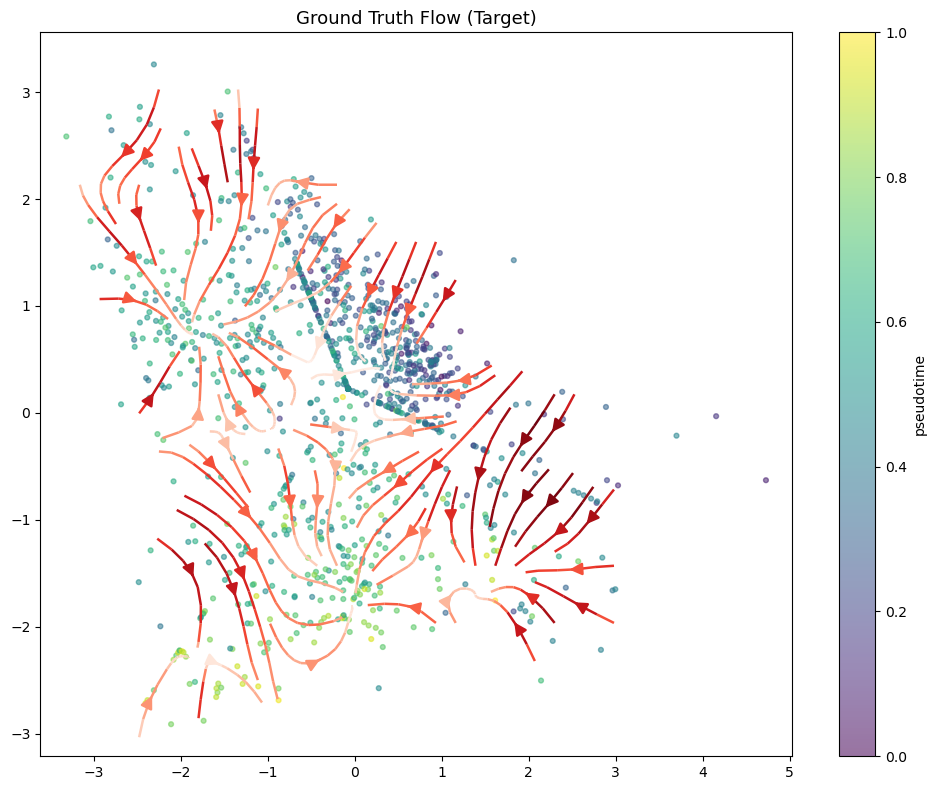

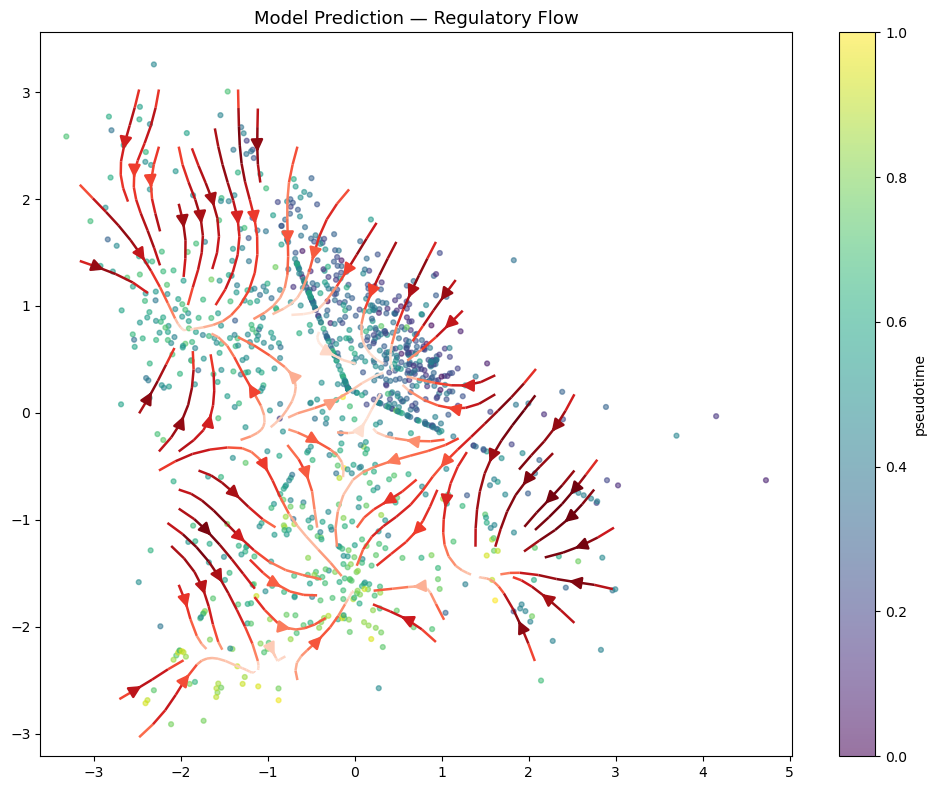

2D cosine alignment (all):       0.794
2D cosine alignment (high-conf): 0.998
Fraction correct (cos>0):        89.9%


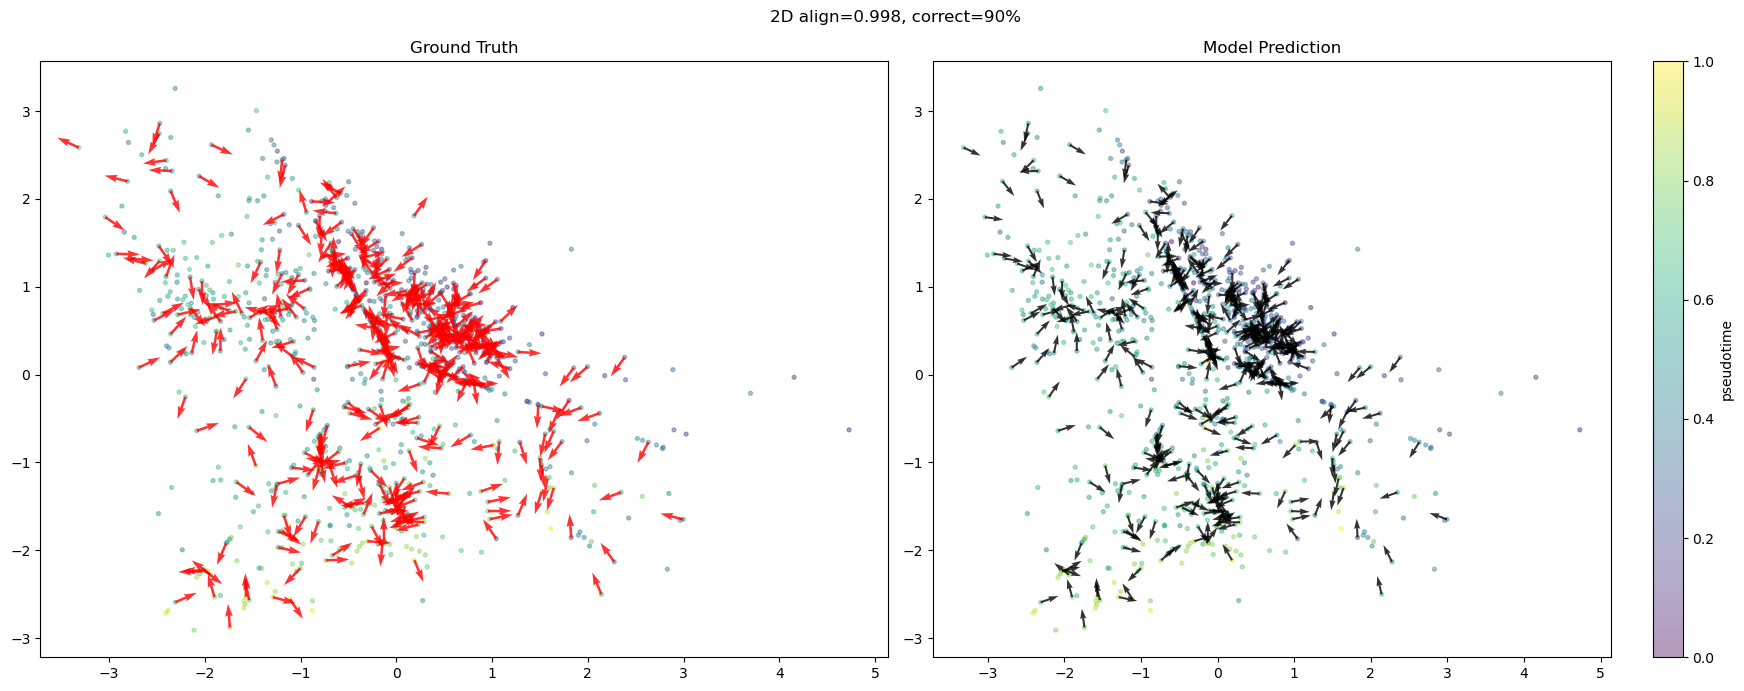

In [39]:
# ============================================================
# STEP 7: Visualization (streamplot directly in V_vis space)
# No projection needed — we predicted in 2D already
# ============================================================

def streamplot_2d(V_vis, V_2d, ps, title, grid_n=40,
                  radius=0.45, sigma=1.0, min_mass=3, save_path=None):
    x_min, x_max = V_vis[:, 0].min() - 0.3, V_vis[:, 0].max() + 0.3
    y_min, y_max = V_vis[:, 1].min() - 0.3, V_vis[:, 1].max() + 0.3
    gx = np.linspace(x_min, x_max, grid_n)
    gy = np.linspace(y_min, y_max, grid_n)

    GU = np.zeros((grid_n, grid_n))
    GV = np.zeros((grid_n, grid_n))
    cnt= np.zeros((grid_n, grid_n))

    nn_g   = NearestNeighbors(radius=radius).fit(V_vis)
    gpts   = np.stack(np.meshgrid(gx, gy), axis=-1).reshape(-1, 2)
    dds, iis = nn_g.radius_neighbors(gpts)

    for k, (dd, ii) in enumerate(zip(dds, iis)):
        if len(ii) < min_mass:
            continue
        row, col = divmod(k, grid_n)
        w  = np.exp(-(dd**2) / (2 * (radius * 0.5)**2))
        w /= w.sum()
        GU[row, col] = w @ V_2d[ii, 0]
        GV[row, col] = w @ V_2d[ii, 1]
        cnt[row, col] = len(ii)

    mask = cnt < min_mass
    GU_s = gaussian_filter(GU, sigma=sigma)
    GV_s = gaussian_filter(GV, sigma=sigma)
    GU_s[mask] = np.nan
    GV_s[mask] = np.nan

    fig, ax = plt.subplots(figsize=(10, 8))
    sc = ax.scatter(V_vis[:, 0], V_vis[:, 1], c=ps,
                    cmap='viridis', s=12, alpha=0.55, zorder=2)
    plt.colorbar(sc, ax=ax, label='pseudotime')
    speed = np.sqrt(np.nan_to_num(GU_s)**2 + np.nan_to_num(GV_s)**2)
    ax.streamplot(gx, gy, GU_s, GV_s,
                  color=speed, cmap='Reds', linewidth=1.8,
                  density=1.3, arrowsize=1.8, zorder=3)
    ax.set_title(title, fontsize=13)
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

V_2d_np_n = V_2d_np / (np.linalg.norm(V_2d_np, axis=1, keepdims=True) + 1e-8)

streamplot_2d(V_vis, V_gt_2d_norm, ps,
              "Ground Truth Flow (Target)",
              save_path="final_target_stream.png")

streamplot_2d(V_vis, V_2d_np_n, ps,
              "Model Prediction — Regulatory Flow",
              save_path="final_pred_stream.png")

# Quiver comparison side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
samp = np.random.choice(N, 400, replace=False)
for ax, V2d, title, col in zip(
    axes,
    [V_gt_2d_norm, V_2d_np_n],
    ["Ground Truth", "Model Prediction"],
    ['red', 'black']
):
    sc = ax.scatter(V_vis[:, 0], V_vis[:, 1], c=ps,
                    cmap='viridis', s=8, alpha=0.4)
    ax.quiver(V_vis[samp, 0], V_vis[samp, 1],
              V2d[samp, 0], V2d[samp, 1],
              color=col, width=0.003, alpha=0.8)
    ax.set_title(title)
plt.colorbar(sc, ax=axes[-1], label='pseudotime')

# Metrics
cos_2d = (V_2d_np_n * V_gt_2d_norm).sum(axis=1)
mask_hc = conf_scores > CONF_THRESH
print(f"2D cosine alignment (all):       {cos_2d.mean():.3f}")
print(f"2D cosine alignment (high-conf): {cos_2d[mask_hc].mean():.3f}")
print(f"Fraction correct (cos>0):        {(cos_2d>0).mean()*100:.1f}%")
plt.suptitle(f"2D align={cos_2d[mask_hc].mean():.3f}, "
             f"correct={( cos_2d>0).mean()*100:.0f}%", fontsize=12)
plt.tight_layout()
plt.savefig("final_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 5: Define model

In [30]:
# ============================================================
# STEP 5 (REWRITE): Predict velocity in Z-space.
# The GRN (U @ V.T * M) maps TF expression → gene weights,
# then a learned projection maps gene weights → Z-velocity.
# This keeps the GRN interpretable while letting the geometry
# stay clean in the low-D space where topology is correct.
# ============================================================
import torch, torch.nn as nn, torch.nn.functional as F

class RegulatoryFlowModel(nn.Module):
    """
    Predicts cell velocity in Decipher Z-space (10D).
    
    Architecture:
      1. Low-rank GRN: A = (U @ V.T) * M  →  production score per gene
      2. Decay term in gene space
      3. A small MLP maps the gene-space signal → Z-space velocity
         (keeps GRN interpretable; MLP just learns the geometry mapping)
    """
    def __init__(self, G, T, K, Z_dim, M):
        super().__init__()
        self.G = G
        self.T = T
        self.K = K
        self.Z_dim = Z_dim

        # GRN factors (interpretable part)
        self.U = nn.Parameter(0.01 * torch.randn(G, K))   # gene embeddings
        self.V = nn.Parameter(0.01 * torch.randn(T, K))   # TF embeddings
        self.register_buffer("M_mask", torch.tensor((M > 0).astype("float32")))

        # Decay (per-gene, physically meaningful)
        self.gamma = nn.Parameter(torch.ones(G) * 0.05)

        # Gene-space signal → Z-space velocity
        # Input: gene-space net velocity (G,) → Output: Z-dim velocity
        # Keep it shallow so gradients flow to U, V cleanly
        self.gene_to_z = nn.Sequential(
            nn.Linear(G, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, Z_dim),
        )

    def forward(self, X_TF, X_genes):
        """
        X_TF   : (N, T) TF expression
        X_genes: (N, G) gene expression (z-scored)
        Returns: V_z (N, Z_dim), A (G, T) GRN matrix
        """
        # 1. GRN: TF → gene production
        A = (self.U @ self.V.T) * self.M_mask   # (G, T)
        production = X_TF @ A.T                  # (N, G)

        # 2. Decay
        decay = X_genes * torch.abs(self.gamma)  # (N, G)

        # 3. Net gene-space signal
        net_signal = production - decay           # (N, G)

        # 4. Map to Z-space
        V_z = self.gene_to_z(net_signal)         # (N, Z_dim)

        return V_z, A, net_signal


# ── Loss functions (all operating in clean Z-space) ───────────────────────

def direction_loss(V_pred_z, V_target_z, conf):
    """
    Core supervision: align predicted Z-velocity with target Z-velocity.
    Uses confidence weighting; penalizes wrong-direction harder.
    """
    V_pn = F.normalize(V_pred_z, dim=1)
    V_tn = F.normalize(V_target_z, dim=1)
    cos  = (V_pn * V_tn).sum(dim=1)             # (N,)
    # Asymmetric: wrong direction costs 2x more than imperfect alignment
    loss = torch.where(cos > 0, 1.0 - cos, 2.0 - cos)
    return (conf * loss).mean()


def neighbor_consistency_loss(V_pred_z, nn_idx):
    """
    Smoothness in Z-space: nearby cells should have similar velocities.
    This replaces the old manifold_departure_penalty which needed nn_idx.
    """
    V_n     = F.normalize(V_pred_z, dim=1)       # (N, Z)
    nbr_V   = V_n[nn_idx]                         # (N, k, Z)
    cos_diff = 1.0 - (V_n.unsqueeze(1) * nbr_V).sum(dim=2)
    return cos_diff.mean()


def grn_sparsity_loss(A):
    """L1 on GRN for interpretability."""
    return A.abs().mean()


def grn_diversity_loss(V):
    """Prevent TF embeddings from collapsing to same direction."""
    V_n = F.normalize(V, dim=1)                  # (K, T) nope — (T, K)
    gram = V_n @ V_n.T                            # (T, T)
    eye  = torch.eye(gram.shape[0], device=gram.device)
    return (gram - eye).pow(2).mean()


def velocity_smoothness_field(V_pred_z, Z_dec_t, nn_idx):
    """
    Stronger smoothness: velocity should vary smoothly along the manifold.
    Penalizes large velocity differences for close Z-neighbors.
    """
    V_n     = V_pred_z                           # (N, Z)
    nbr_V   = V_n[nn_idx]                        # (N, k, Z)
    # Distance-weighted: closer neighbors should match more
    diff    = (V_n.unsqueeze(1) - nbr_V).norm(dim=2)   # (N, k)
    return diff.mean()

In [16]:
# How many targets actually point toward the future?
V_target_n = F.normalize(V_target_t, dim=1)
nbr_X = X_t[nn_idx]
delta_n = F.normalize(nbr_X - X_t.unsqueeze(1), dim=2)
# Average alignment of your TARGET with the neighbors
target_alignment = (V_target_n.unsqueeze(1) * delta_n).sum(dim=2).mean()
print(f"Target Alignment: {target_alignment.item():.4f}") 
# If this is < 0.1, Step 4 is the culprit, not Step 6.

NameError: name 'nn_idx' is not defined

## Step 6: Train model

In [31]:
# ============================================================
# STEP 6 (FIXED TRAINING LOOP)
# Key changes from previous version:
#   1. Confidence threshold: ignore cells with conf < 0.2
#   2. Margin cosine loss: only penalize if cos < 0.5 (not just < 1)
#   3. Remove velocity_smoothness_field (was over-smoothing into sink)
#   4. Increase grn_diverse weight to prevent embedding collapse
# ============================================================
from scipy.stats import zscore

Z_dim  = Z_dec.shape[1]
G_dim  = X.shape[1]
T_dim  = X_TF.shape[1]
K_rank = 30

model = RegulatoryFlowModel(G_dim, T_dim, K_rank, Z_dim, M).to(device)
opt   = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=3e-3, total_steps=600, pct_start=0.1, final_div_factor=100
)

CONF_THRESH = 0.2    # ignore cells below this confidence
COS_MARGIN  = 0.3    # only penalize if cosine similarity < this

def direction_loss_with_margin(V_pred_z, V_target_z, conf, 
                                conf_thresh=CONF_THRESH, margin=COS_MARGIN):
    """
    Margin cosine loss on high-confidence cells only.
    No penalty if cos(pred, target) > margin — avoids over-fitting noise.
    """
    # Only train on cells where we're confident about the direction
    mask    = conf > conf_thresh
    if mask.sum() < 10:
        return torch.tensor(0.0, device=V_pred_z.device)
    
    V_pn    = F.normalize(V_pred_z[mask], dim=1)
    V_tn    = F.normalize(V_target_z[mask], dim=1)
    cos     = (V_pn * V_tn).sum(dim=1)             # (n_high_conf,)
    
    # Margin: no loss if already well-aligned; large penalty if opposed
    loss    = torch.relu(margin - cos)              # hinge at margin
    w       = conf[mask]
    return (w * loss).sum() / (w.sum() + 1e-8)


def neighbor_consistency_loss(V_pred_z, nn_idx):
    V_n   = F.normalize(V_pred_z, dim=1)
    nbr_V = V_n[nn_idx]
    return (1.0 - (V_n.unsqueeze(1) * nbr_V).sum(dim=2)).mean()


def grn_sparsity_loss(A):
    return A.abs().mean()


def grn_diversity_loss(V_param):
    V_n  = F.normalize(V_param, dim=1)
    gram = V_n @ V_n.T
    eye  = torch.eye(gram.shape[0], device=gram.device)
    return (gram - eye).pow(2).mean()


W = dict(
    direction   = 100.0,
    consistency = 3.0,    # reduced: was causing smoothing into sink
    grn_sparse  = 0.1,
    grn_diverse = 2.0,    # increased: prevents embedding collapse
)

print(f"Training on {N} cells, "
      f"{(conf_scores > CONF_THRESH).sum()} above confidence threshold")

for epoch in range(601):
    model.train()
    opt.zero_grad()

    V_z_pred, A, _ = model(X_TF_t, X_z_t)

    l_dir   = direction_loss_with_margin(V_z_pred, V_target_z_t, conf_t)
    l_cons  = neighbor_consistency_loss(V_z_pred, nn_idx)
    l_sparse= grn_sparsity_loss(A)
    l_div   = grn_diversity_loss(model.V)

    loss = (W["direction"]   * l_dir   +
            W["consistency"] * l_cons  +
            W["grn_sparse"]  * l_sparse+
            W["grn_diverse"] * l_div)

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    sched.step()

    with torch.no_grad():
        model.gamma.data.clamp_(0.005, 0.5)

    if epoch % 50 == 0:
        with torch.no_grad():
            mask = conf_t > CONF_THRESH
            V_n  = F.normalize(V_z_pred[mask], dim=1)
            Vt_n = F.normalize(V_target_z_t[mask], dim=1)
            align_hc = (V_n * Vt_n).sum(dim=1).mean().item()
            # Also check: do arrows point away from cluster center?
            center   = Z_dec_t.mean(dim=0)
            outward  = F.normalize(Z_dec_t - center, dim=1)
            outwardness = (F.normalize(V_z_pred, dim=1) * outward).sum(dim=1).mean().item()
        print(f"[{epoch:3d}] Loss={loss.item():.3f} | Dir={l_dir.item():.4f} | "
              f"HighConfAlign={align_hc:.4f} | Outwardness={outwardness:+.4f}")

model.eval()
with torch.no_grad():
    V_z_final, A_final, _ = model(X_TF_t, X_z_t)

V_z_np = V_z_final.cpu().numpy()
A_np   = A_final.cpu().numpy()
print(f"\nOutwardness > 0 means arrows point away from center (correct for branching)")

Training on 1035 cells, 406 above confidence threshold
[  0] Loss=35.140 | Dir=0.3386 | HighConfAlign=-0.0125 | Outwardness=+0.0469
[ 50] Loss=0.554 | Dir=0.0005 | HighConfAlign=0.5314 | Outwardness=-0.1812
[100] Loss=0.385 | Dir=0.0004 | HighConfAlign=0.4961 | Outwardness=-0.1573
[150] Loss=0.281 | Dir=0.0001 | HighConfAlign=0.4750 | Outwardness=-0.1335
[200] Loss=0.270 | Dir=0.0005 | HighConfAlign=0.4560 | Outwardness=-0.1294
[250] Loss=0.208 | Dir=0.0000 | HighConfAlign=0.4585 | Outwardness=-0.1108
[300] Loss=0.195 | Dir=0.0000 | HighConfAlign=0.4446 | Outwardness=-0.0998
[350] Loss=0.173 | Dir=0.0001 | HighConfAlign=0.4340 | Outwardness=-0.0912
[400] Loss=0.160 | Dir=0.0000 | HighConfAlign=0.4219 | Outwardness=-0.0888
[450] Loss=0.149 | Dir=0.0000 | HighConfAlign=0.4099 | Outwardness=-0.0869
[500] Loss=0.149 | Dir=0.0001 | HighConfAlign=0.4045 | Outwardness=-0.0834
[550] Loss=0.138 | Dir=0.0000 | HighConfAlign=0.4020 | Outwardness=-0.0782


ValueError: Tried to step 601 times. The specified number of total steps is 600

In [32]:
model.eval()
with torch.no_grad():
    V_z_final, A_final, _ = model(X_TF_t, X_z_t)

V_z_np = V_z_final.cpu().numpy()
A_np   = A_final.cpu().numpy()
print(f"\nOutwardness > 0 means arrows point away from center (correct for branching)")


Outwardness > 0 means arrows point away from center (correct for branching)


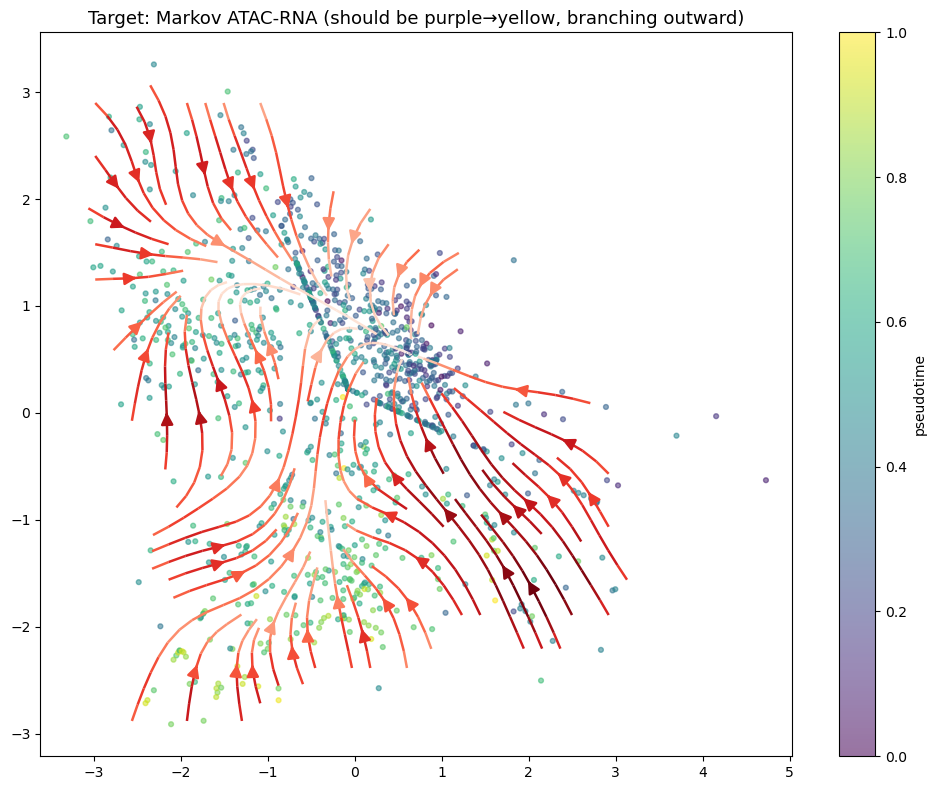

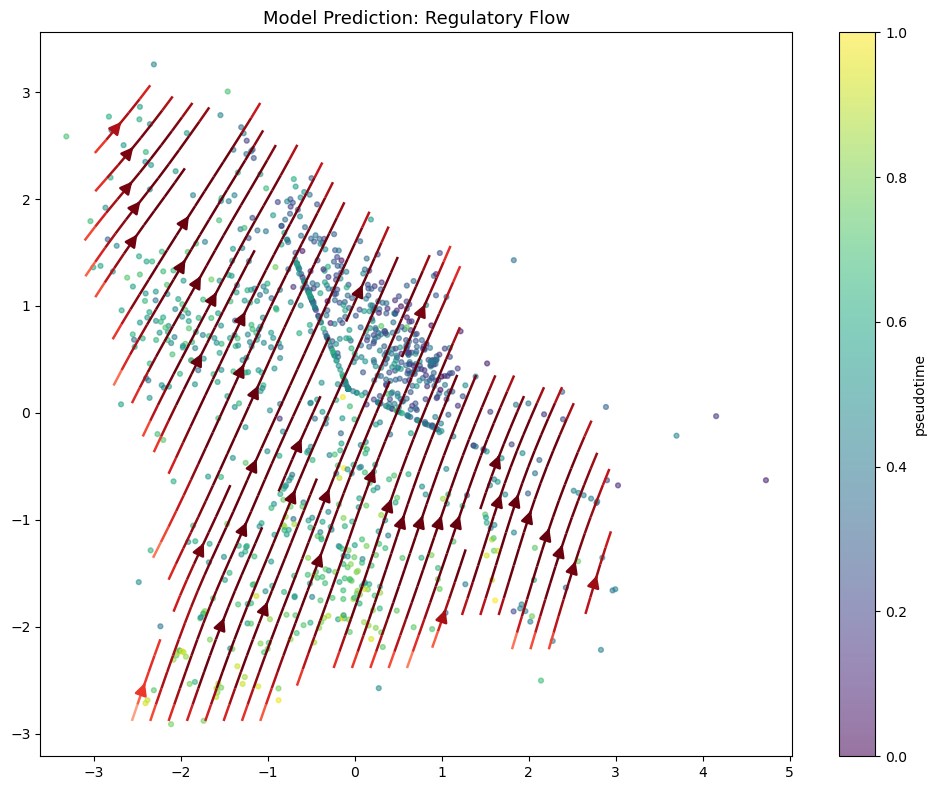

2D cosine alignment (pred vs target): 0.211 ± 0.649
Fraction correct direction (cos>0):   63.9%
Alignment with pseudotime gradient:   -0.9760 (positive = correct direction)


In [33]:
# ============================================================
# STEP 7 (FINAL): Jacobian projection + streamplot
# Uses the Ridge regression Jacobian from Step 4 (J_z2vis)
# which is already fit and available in your namespace.
# ============================================================
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

# ── 7A. Project Z-velocity → 2D using Jacobian (from Step 4) ─────────────
# J_z2vis shape: (2, Z_dim)
# This is the correct projection: it uses the global linear map from
# Decipher's embedding, not cosine-weighted neighbor averaging.
V_2d_pred   = (J_z2vis @ V_z_np.T).T              # (N, 2)
V_2d_target = (J_z2vis @ V_target_z_norm.T).T     # (N, 2)

V_2d_pred_n   = V_2d_pred   / (np.linalg.norm(V_2d_pred,   axis=1, keepdims=True) + 1e-8)
V_2d_target_n = V_2d_target / (np.linalg.norm(V_2d_target, axis=1, keepdims=True) + 1e-8)

# ── 7B. Streamplot with grid averaging ───────────────────────────────────
def make_streamplot(V_vis, V_2d, ps, title, save_path=None,
                    grid_n=35, radius=0.5, sigma=1.2, min_mass=3):
    x_min, x_max = V_vis[:, 0].min() - 0.3, V_vis[:, 0].max() + 0.3
    y_min, y_max = V_vis[:, 1].min() - 0.3, V_vis[:, 1].max() + 0.3

    gx = np.linspace(x_min, x_max, grid_n)
    gy = np.linspace(y_min, y_max, grid_n)
    GU = np.full((grid_n, grid_n), np.nan)
    GV = np.full((grid_n, grid_n), np.nan)

    nn_g = NearestNeighbors(radius=radius).fit(V_vis)
    gpts = np.stack(np.meshgrid(gx, gy), axis=-1).reshape(-1, 2)
    res  = nn_g.radius_neighbors(gpts)

    for k, (dd, ii) in enumerate(zip(*res)):
        if len(ii) < min_mass:
            continue
        gy_k, gx_k = divmod(k, grid_n)
        w = np.exp(-(dd**2) / (2 * (radius * 0.4)**2))
        w /= w.sum()
        GU[gy_k, gx_k] = np.dot(w, V_2d[ii, 0])
        GV[gy_k, gx_k] = np.dot(w, V_2d[ii, 1])

    # Fill NaN with 0 for smoothing, then re-mask
    mask_nan = np.isnan(GU)
    GU_s = gaussian_filter(np.nan_to_num(GU), sigma=sigma)
    GV_s = gaussian_filter(np.nan_to_num(GV), sigma=sigma)
    GU_s[mask_nan] = np.nan
    GV_s[mask_nan] = np.nan

    speed = np.sqrt(GU_s**2 + GV_s**2)

    fig, ax = plt.subplots(figsize=(10, 8))
    sc = ax.scatter(V_vis[:, 0], V_vis[:, 1], c=ps,
                    cmap='viridis', s=12, alpha=0.55, zorder=2)
    plt.colorbar(sc, ax=ax, label='pseudotime')
    strm = ax.streamplot(gx, gy, GU_s, GV_s,
                         color=speed, cmap='Reds',
                         linewidth=1.8, density=1.4,
                         arrowsize=1.8, zorder=3)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(title, fontsize=13)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return GU_s, GV_s


from sklearn.neighbors import NearestNeighbors  # ensure imported

GU_t, GV_t = make_streamplot(
    V_vis, V_2d_target_n, ps,
    title="Target: Markov ATAC-RNA (should be purple→yellow, branching outward)",
    save_path="step7_target_stream.png"
)

GU_p, GV_p = make_streamplot(
    V_vis, V_2d_pred_n, ps,
    title="Model Prediction: Regulatory Flow",
    save_path="step7_pred_stream.png"
)

# ── 7C. Quantitative sanity checks ───────────────────────────────────────
cos_2d = (V_2d_pred_n * V_2d_target_n).sum(axis=1)
print(f"2D cosine alignment (pred vs target): {cos_2d.mean():.3f} ± {cos_2d.std():.3f}")
print(f"Fraction correct direction (cos>0):   {(cos_2d > 0).mean()*100:.1f}%")

# Pseudotime correlation: do arrows point toward higher pseudotime?
ps_grad_2d = LinearRegression().fit(V_vis, ps).coef_
ps_grad_2d /= np.linalg.norm(ps_grad_2d) + 1e-8
ps_align = (V_2d_pred_n @ ps_grad_2d).mean()
print(f"Alignment with pseudotime gradient:   {ps_align:+.4f} (positive = correct direction)")

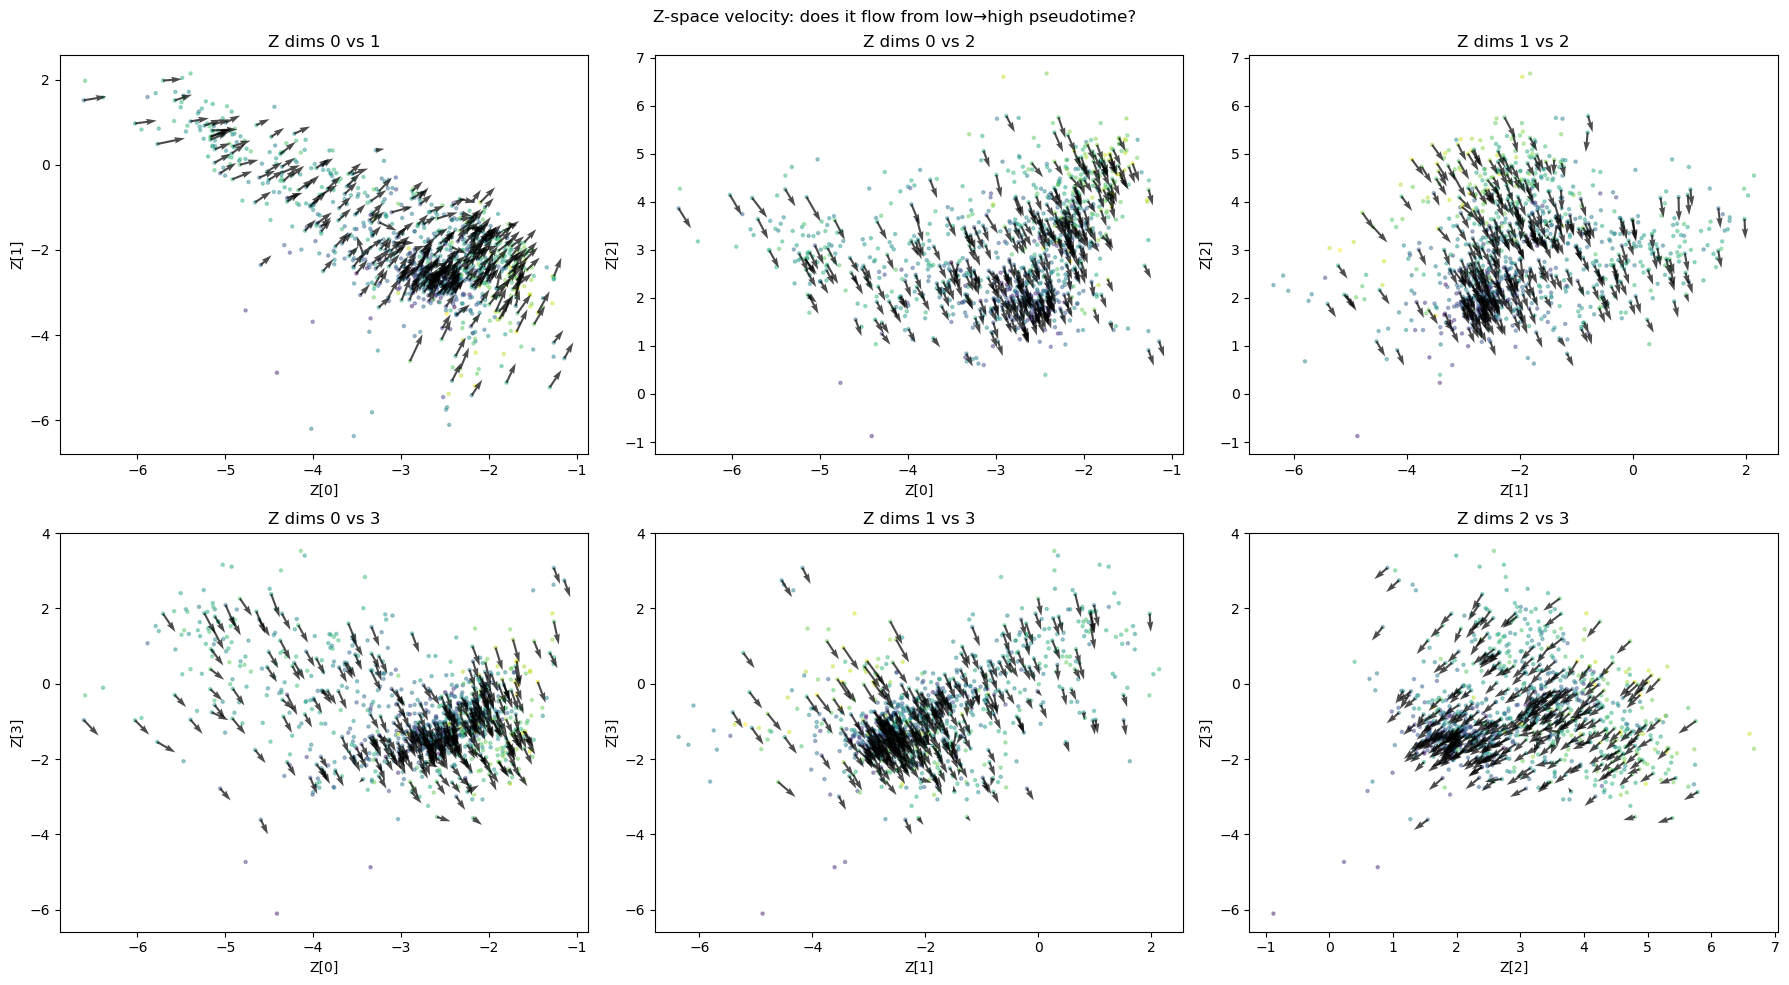

In [34]:
# ============================================================
# DIAGNOSTIC: Is the Z-velocity correct before projection?
# Plot arrows directly in each Z-dimension pair.
# If these look right, the model is fine and only projection is broken.
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

ps = rna_adata.obs["facs_pseudotime"].values
samp = np.random.choice(N, 300, replace=False)

dim_pairs = [(0,1), (0,2), (1,2), (0,3), (1,3), (2,3)]
for ax, (d1, d2) in zip(axes, dim_pairs):
    ax.scatter(Z_dec[:, d1], Z_dec[:, d2], c=ps, cmap='viridis', s=5, alpha=0.4)
    ax.quiver(
        Z_dec[samp, d1], Z_dec[samp, d2],
        V_z_np[samp, d1], V_z_np[samp, d2],
        color='black', alpha=0.7, width=0.004
    )
    ax.set_xlabel(f"Z[{d1}]"); ax.set_ylabel(f"Z[{d2}]")
    ax.set_title(f"Z dims {d1} vs {d2}")

plt.suptitle("Z-space velocity: does it flow from low→high pseudotime?", fontsize=12)
plt.tight_layout()
plt.savefig("z_velocity_diagnostic.png", dpi=120, bbox_inches='tight')
plt.show()

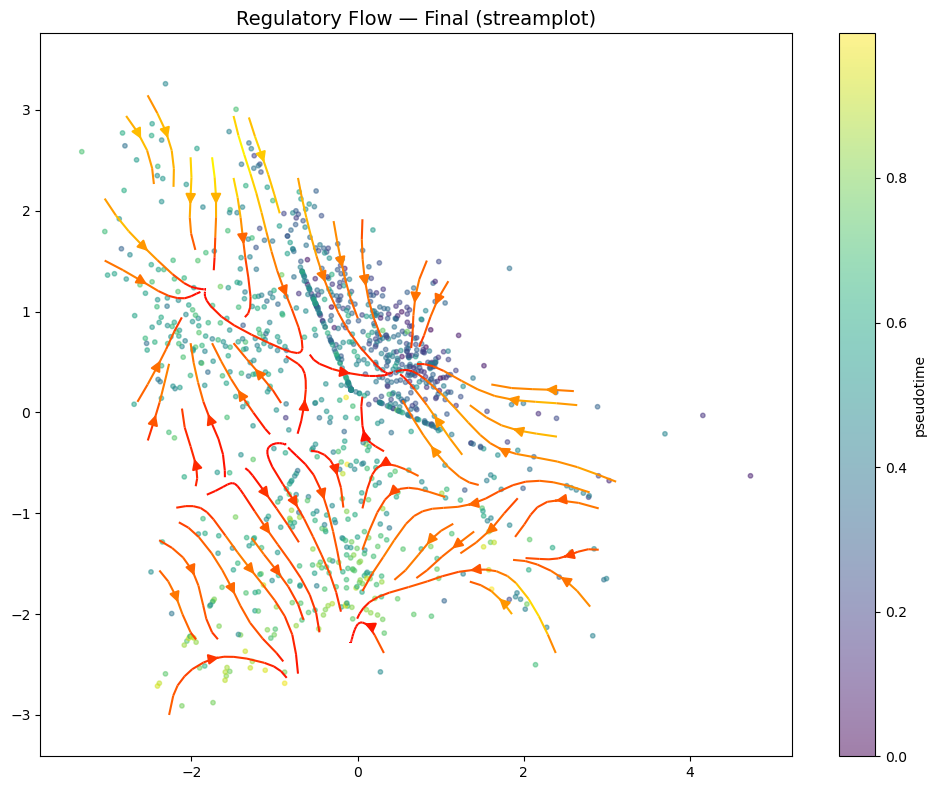

In [26]:
# ============================================================
# STEP 7B: PI-ready streamplot using grid averaging
# ============================================================
from matplotlib.colors import Normalize
from scipy.stats import gaussian_kde

def velocity_streamplot(V_vis, V_2d, ps, title="Velocity Field", 
                         grid_n=40, min_mass=2, save_path=None):
    """
    Aggregate cell velocities onto a regular grid, then streamplot.
    Much cleaner than quiver for showing global flow patterns.
    """
    # Grid boundaries
    x_min, x_max = V_vis[:, 0].min() - 0.5, V_vis[:, 0].max() + 0.5
    y_min, y_max = V_vis[:, 1].min() - 0.5, V_vis[:, 1].max() + 0.5
    
    gx = np.linspace(x_min, x_max, grid_n)
    gy = np.linspace(y_min, y_max, grid_n)
    GX, GY = np.meshgrid(gx, gy)
    grid_pts = np.stack([GX.ravel(), GY.ravel()], axis=1)
    
    # For each grid point, find nearby cells and average their velocity
    from sklearn.neighbors import NearestNeighbors
    nn_grid = NearestNeighbors(radius=0.4).fit(V_vis)
    results = nn_grid.radius_neighbors(grid_pts)
    
    GU = np.zeros(grid_n * grid_n)
    GV_arr = np.zeros(grid_n * grid_n)
    mass   = np.zeros(grid_n * grid_n)
    
    for k, (dists_k, idx_k) in enumerate(zip(*results)):
        if len(idx_k) >= min_mass:
            # Gaussian-weighted average
            w = np.exp(-(dists_k**2) / (2 * 0.2**2))
            w /= w.sum()
            GU[k]   = np.dot(w, V_2d[idx_k, 0])
            GV_arr[k] = np.dot(w, V_2d[idx_k, 1])
            mass[k] = len(idx_k)
    
    # Mask empty grid cells
    mask = mass >= min_mass
    GU   = GU.reshape(grid_n, grid_n)
    GV_arr = GV_arr.reshape(grid_n, grid_n)
    mass = mass.reshape(grid_n, grid_n)
    
    # Smooth
    from scipy.ndimage import gaussian_filter
    GU   = gaussian_filter(GU,   sigma=1.0)
    GV_arr = gaussian_filter(GV_arr, sigma=1.0)
    GU[mass < min_mass]   = np.nan
    GV_arr[mass < min_mass] = np.nan
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sc = ax.scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis',
                    s=10, alpha=0.5, zorder=2)
    plt.colorbar(sc, ax=ax, label='pseudotime')
    
    speed = np.sqrt(GU**2 + GV_arr**2)
    ax.streamplot(gx, gy, GU, GV_arr,
                  color=speed, cmap='autumn', linewidth=1.5,
                  density=1.2, arrowsize=1.5, zorder=3)
    
    ax.set_title(title, fontsize=14)
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


velocity_streamplot(V_vis, V_2d_pred, ps,
                    title="Regulatory Flow — Final (streamplot)",
                    save_path="regulatory_flow_streamplot.png")

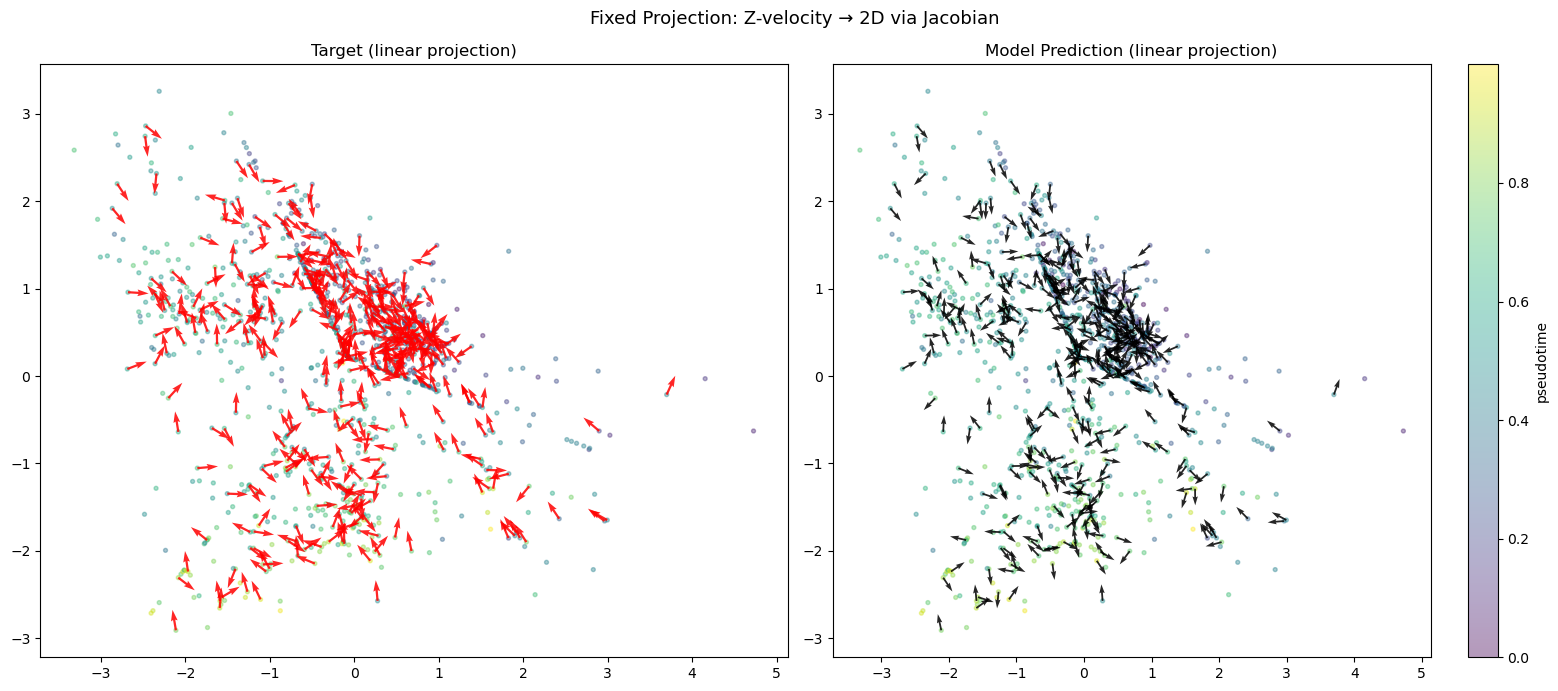

In [24]:
# ============================================================
# STEP 7 (FIXED): Project Z-velocity → 2D using global linear map
# 
# Why: cosine-weighted neighbor projection fails when neighbors
# are arranged radially (as in your star-shaped manifold).
# A linear map from Z → 2D is learned from the Z structure itself
# and is unbiased by local neighborhood geometry.
# ============================================================
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt

def project_velocity_to_2d_linear(V_z, Z_dec, V_vis, alpha=1.0):
    """
    Learn a linear map: Z_displacement → V_vis_displacement
    by using the global Z structure.
    
    The key insight: if we know how Z coordinates relate to V_vis 
    coordinates (via a linear map), we can directly apply that 
    map to Z-velocities to get 2D velocities.
    """
    # The Decipher embedding itself gives us the map:
    # Z_dec → V_vis is approximately linear (Decipher is a linear decoder).
    # So dV_vis/dt ≈ J @ dZ/dt where J is the Jacobian.
    # We estimate J by regression: V_vis ~ Z_dec @ J.T
    
    reg = Ridge(alpha=alpha, fit_intercept=True)
    reg.fit(Z_dec, V_vis)           # learn Z → 2D
    J = reg.coef_                   # (2, Z_dim) — the Jacobian approximation
    
    # Apply Jacobian to Z-velocities
    V_2d = V_z @ J.T               # (N, 2)
    return V_2d, J

V_2d_pred,   J = project_velocity_to_2d_linear(V_z_np,          Z_dec, V_vis)
V_2d_target, _ = project_velocity_to_2d_linear(V_target_z_norm, Z_dec, V_vis)

# Normalize for display
def norm2d(v):
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)

V_2d_pred_n   = norm2d(V_2d_pred)
V_2d_target_n = norm2d(V_2d_target)

# Plot
ps = rna_adata.obs["facs_pseudotime"].values
samp = np.random.choice(N, 400, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, V2d, title, col in zip(
    axes,
    [V_2d_target_n, V_2d_pred_n],
    ["Target (linear projection)", "Model Prediction (linear projection)"],
    ['red', 'black']
):
    sc = ax.scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis', s=8, alpha=0.4)
    ax.quiver(V_vis[samp, 0], V_vis[samp, 1],
              V2d[samp, 0], V2d[samp, 1],
              color=col, width=0.003, alpha=0.85)
    ax.set_title(title)
plt.colorbar(sc, ax=axes[1], label='pseudotime')
plt.suptitle("Fixed Projection: Z-velocity → 2D via Jacobian", fontsize=13)
plt.tight_layout()
plt.savefig("regulatory_flow_fixed_projection.png", dpi=150, bbox_inches='tight')
plt.show()

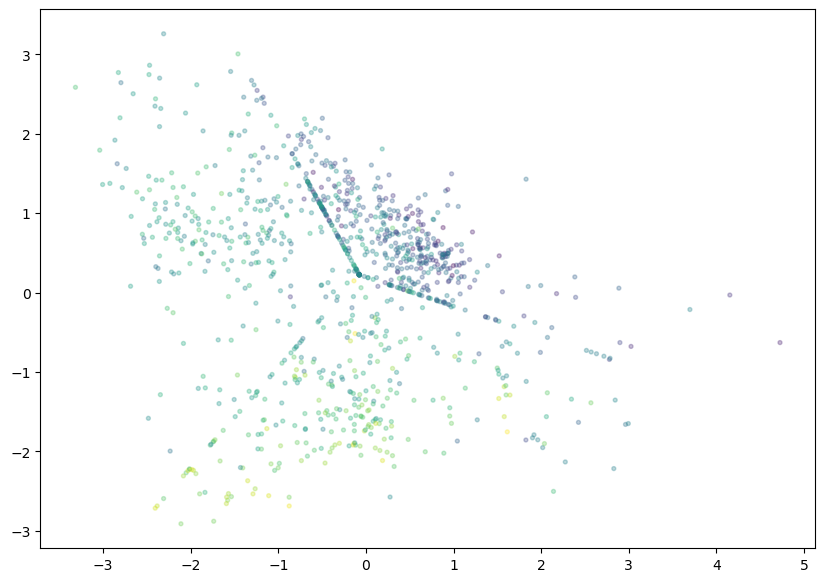

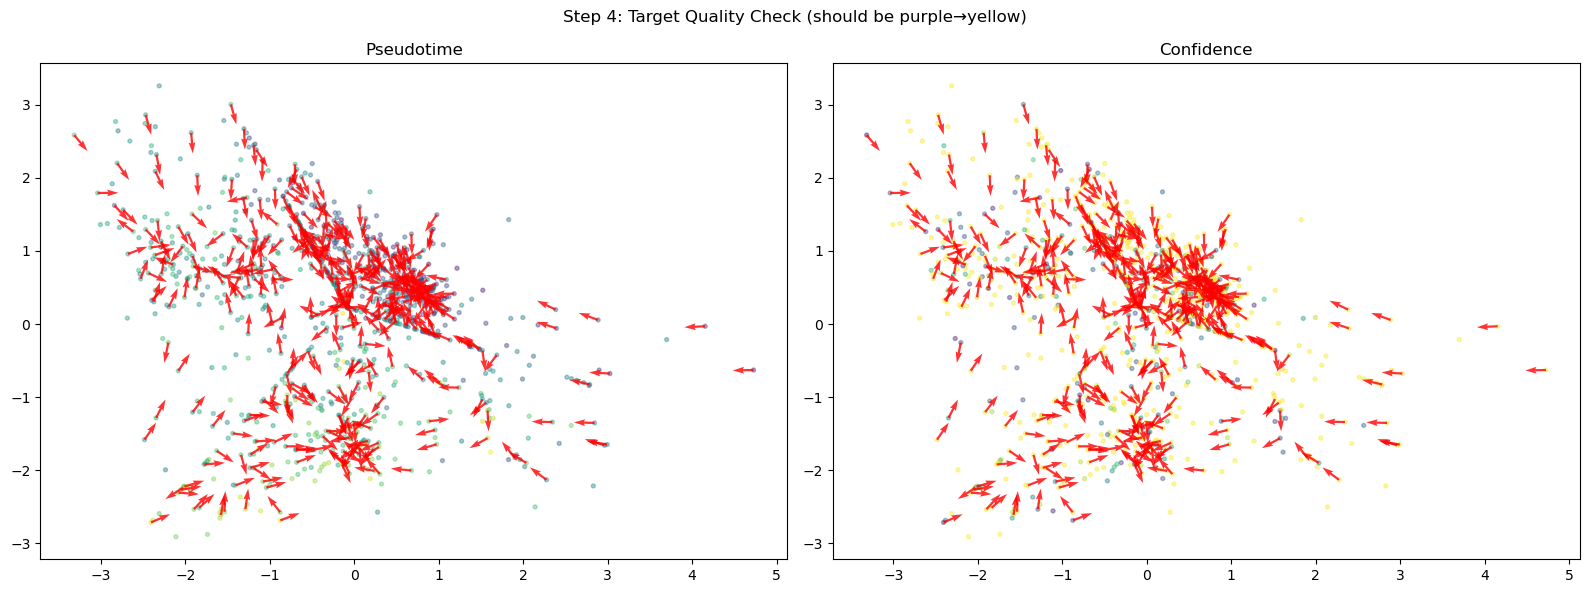

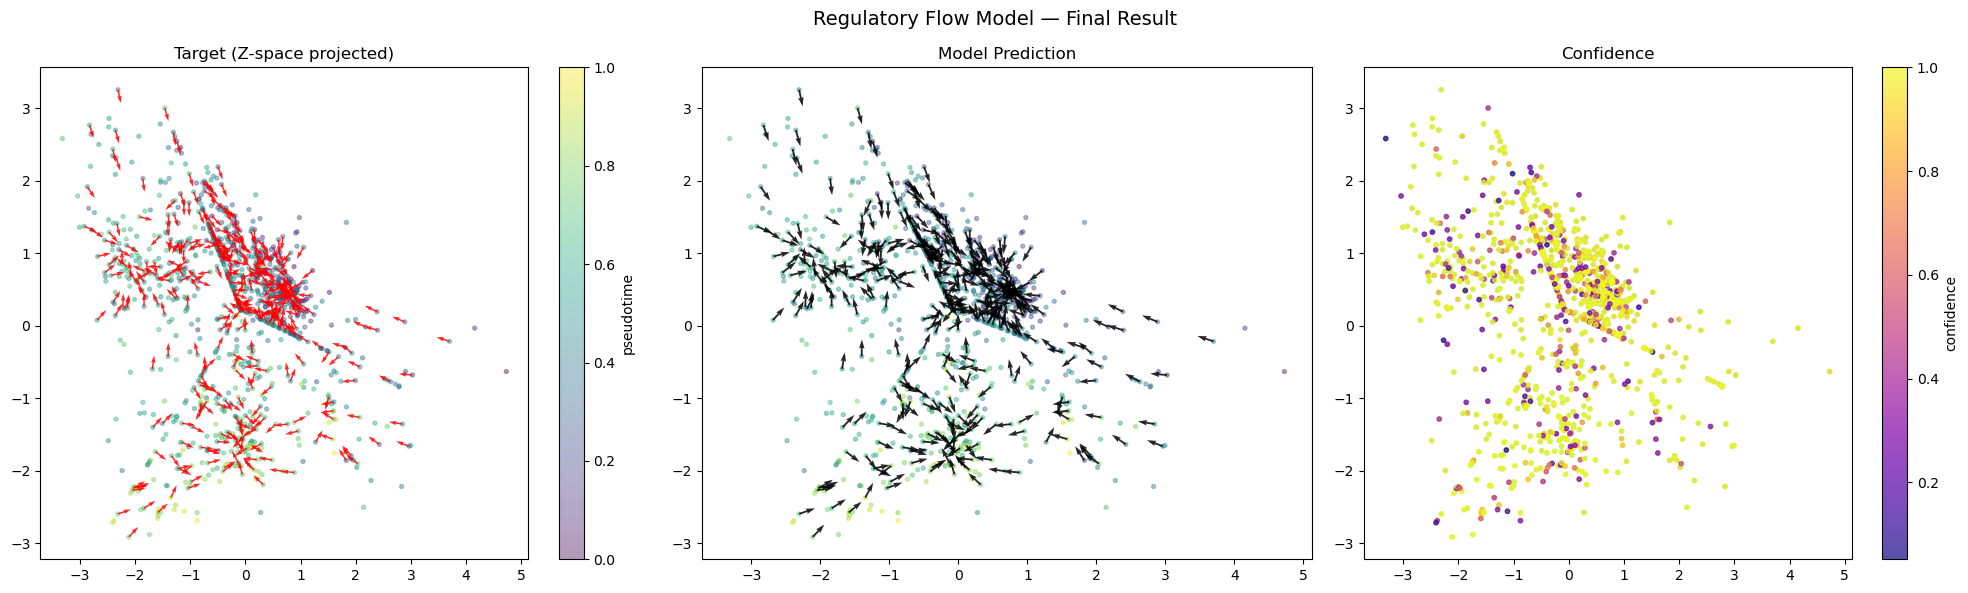

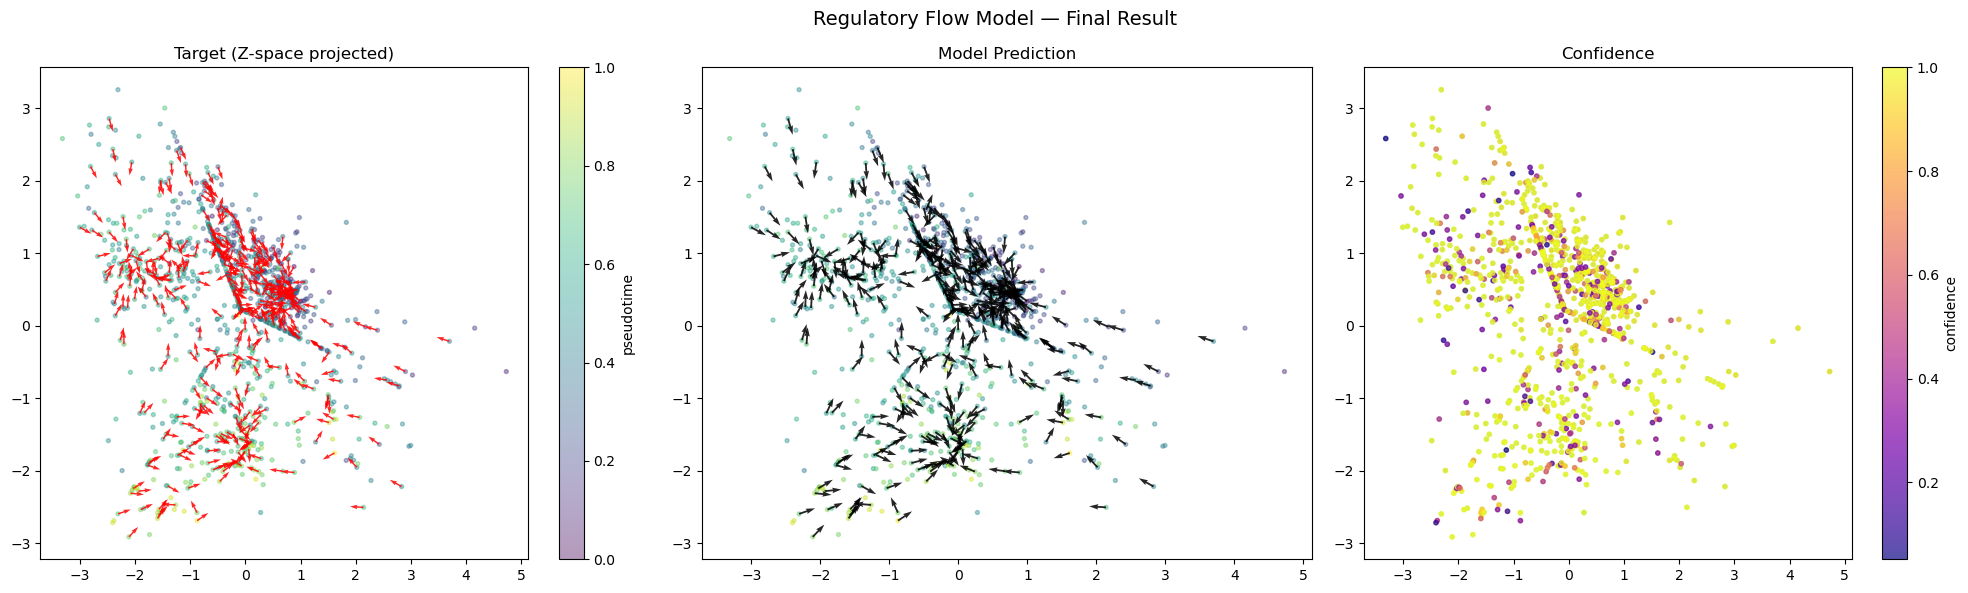


2D cosine alignment (pred vs target): 0.994 ± 0.067
Fraction correct direction (cos > 0): 99.9%


In [21]:
# ============================================================
# STEP 7: Visualization in 2D Decipher space
# Project Z-velocity → 2D using neighbor transition probabilities
# (same method as scVelo's streamplot projection)
# ============================================================
from sklearn.neighbors import NearestNeighbors
%matplotlib inline
def project_velocity_to_2d(V_z, Z_dec, V_vis, k=30):
    """
    Project Z-space velocity to 2D visualization coords.
    
    Method: for each cell, compute cosine similarity between its
    Z-velocity and the direction to each Z-neighbor, then use
    those as weights to combine the 2D displacements.
    This is equivalent to scVelo's transition matrix approach.
    """
    N = Z_dec.shape[0]
    nn = NearestNeighbors(n_neighbors=k + 1, metric='euclidean').fit(Z_dec)
    dists, idx = nn.kneighbors(Z_dec)
    idx = idx[:, 1:]; dists = dists[:, 1:]

    V_2d = np.zeros((N, 2), dtype=np.float32)

    for i in range(N):
        v_z = V_z[i]                              # (Z_dim,)
        nbr_idx = idx[i]                           # (k,)
        
        # Displacement vectors in Z-space to each neighbor
        dz = Z_dec[nbr_idx] - Z_dec[i]            # (k, Z_dim)
        
        # Cosine similarity: velocity direction vs. neighbor direction
        v_norm  = v_z / (np.linalg.norm(v_z) + 1e-8)
        dz_norm = dz / (np.linalg.norm(dz, axis=1, keepdims=True) + 1e-8)
        cos_sim = dz_norm @ v_norm                 # (k,)
        
        # Softmax weighting (temperature=0.3 keeps it sharp)
        w = np.exp(cos_sim / 0.3)
        w /= (w.sum() + 1e-8)
        
        # Weighted combination of 2D displacements
        d_vis = V_vis[nbr_idx] - V_vis[i]         # (k, 2)
        V_2d[i] = w @ d_vis

    return V_2d


V_2d_pred   = project_velocity_to_2d(V_z_np,           Z_dec, V_vis)
V_2d_target = project_velocity_to_2d(V_target_z_norm,  Z_dec, V_vis)

# Normalize
V_2d_pred   /= (np.linalg.norm(V_2d_pred,   axis=1, keepdims=True) + 1e-8)
V_2d_target /= (np.linalg.norm(V_2d_target, axis=1, keepdims=True) + 1e-8)

# ── Final plot ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

samp = np.random.choice(N, 400, replace=False)
titles   = ["Target (Z-space projected)", "Model Prediction", "Confidence"]
datasets = [V_2d_target, V_2d_pred, None]
colors   = ['red', 'black', None]

for ax, title, V2d, col in zip(axes, titles, datasets, colors):
    sc = ax.scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis', s=8, alpha=0.4)
    if V2d is not None:
        ax.quiver(V_vis[samp, 0], V_vis[samp, 1],
                  V2d[samp, 0], V2d[samp, 1],
                  color=col, width=0.003, alpha=0.85)
    else:
        sc2 = ax.scatter(V_vis[:, 0], V_vis[:, 1],
                         c=conf_scores, cmap='plasma', s=10, alpha=0.7)
        plt.colorbar(sc2, ax=ax, label='confidence')
    ax.set_title(title)

plt.colorbar(sc, ax=axes[0], label='pseudotime')
plt.suptitle("Regulatory Flow Model — Final Result", fontsize=14)
plt.tight_layout()
plt.savefig("regulatory_flow_final.png", dpi=150, bbox_inches='tight')
plt.show()

# Quantitative alignment check
cos_align = (
    (V_2d_pred / (np.linalg.norm(V_2d_pred, axis=1, keepdims=True) + 1e-8)) *
    (V_2d_target / (np.linalg.norm(V_2d_target, axis=1, keepdims=True) + 1e-8))
).sum(axis=1)
print(f"\n2D cosine alignment (pred vs target): {cos_align.mean():.3f} ± {cos_align.std():.3f}")
print(f"Fraction correct direction (cos > 0): {(cos_align > 0).mean()*100:.1f}%")

Projecting current velocity to 2D...


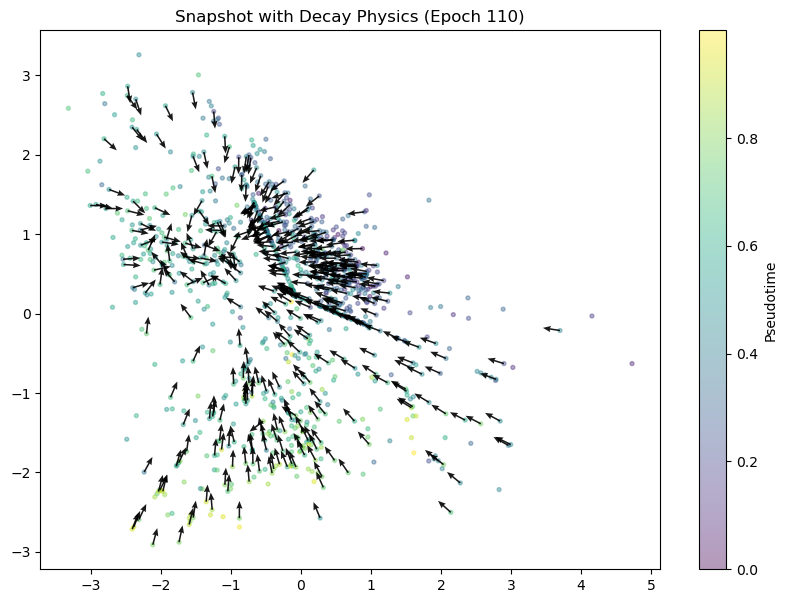

In [28]:
import matplotlib.pyplot as plt
%matplotlib inline

# 1. Get current predictions
model.eval()
with torch.no_grad():
    # PASS BOTH INPUTS NOW
    V_now_t, _ = model(X_TF_t, X_t)  
    V_now = V_now_t.cpu().numpy()

V_dec2 = decipher_data["v"].astype(np.float32)

# 2. Transition-Based Projection to 2D
print("Projecting current velocity to 2D...")
k_proj = 30
nn_proj = NearestNeighbors(n_neighbors=k_proj).fit(X_z) 
_, idx_p = nn_proj.kneighbors(X_z)

V_2d = np.zeros((N, 2))
for i in range(N):
    v_i = V_now[i]
    diffs = X_z[idx_p[i]] - X_z[i]
    
    # Cosine similarity in high-dim gene space
    v_n = v_i / (np.linalg.norm(v_i) + 1e-8)
    d_n = diffs / (np.linalg.norm(diffs, axis=1, keepdims=True) + 1e-8)
    cos_sims = np.dot(d_n, v_n)
    
    # Softmax weights (0.2 is the 'sharpness' of the projection)
    w = np.exp(cos_sims / 0.2) 
    w /= (w.sum() + 1e-8)
    
    vis_diffs = V_dec2[idx_p[i]] - V_dec2[i]
    V_2d[i] = np.dot(w, vis_diffs)

# Normalize for visualization
V_2d /= (np.linalg.norm(V_2d, axis=1, keepdims=True) + 1e-8)

# 3. Plot
plt.figure(figsize=(10, 7))
# Plot cells
plt.scatter(V_dec2[:, 0], V_dec2[:, 1], c=rna_adata.obs["facs_pseudotime"], 
            cmap='viridis', s=8, alpha=0.4)
plt.colorbar(label='Pseudotime')

# Plot arrows
samp = np.random.choice(N, 400, replace=False) # slightly more arrows
plt.quiver(V_dec2[samp, 0], V_dec2[samp, 1], V_2d[samp, 0], V_2d[samp, 1], 
           color='black', alpha=0.9, width=0.0025, headwidth=4)

plt.title(f"Snapshot with Decay Physics (Epoch {epoch})")
plt.show()

/tmp/ipykernel_3500/11474154.py:33: RuntimeWarning: divide by zero encountered in divide
/tmp/ipykernel_3500/11474154.py:33: RuntimeWarning: invalid value encountered in divide


Branch-Aware Target Rebuilt. Check the 'Flow' now.


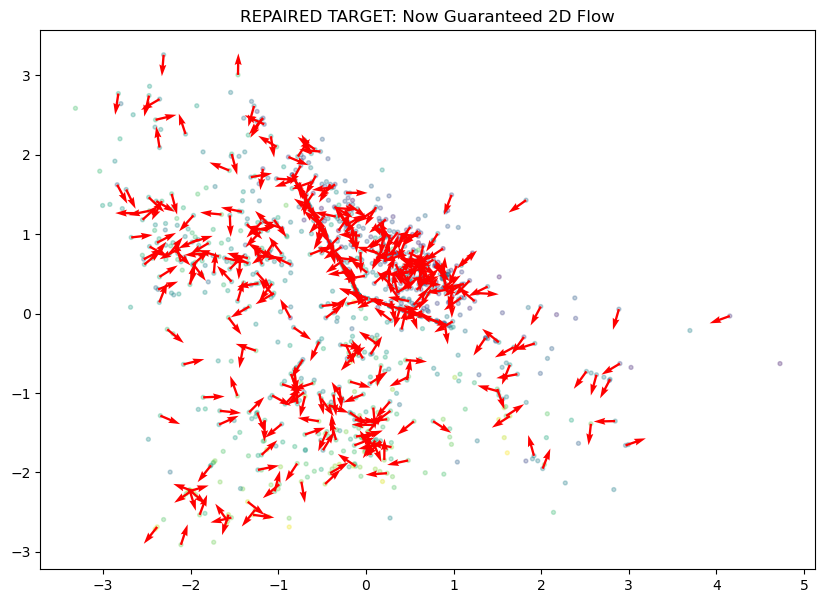

In [62]:
import torch
import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1. Use 2D coordinates for logic, 11k-D for model
V_vis = decipher_data["v"].astype(np.float32)
X_full = X.astype(np.float32) # Using the full gene space for maximum signal
ps = rna_adata.obs["facs_pseudotime"].values

# 2. Tight neighborhood to prevent "jumping" between branches
nn_vis = NearestNeighbors(n_neighbors=15).fit(V_vis)
_, idx_vis = nn_vis.kneighbors(V_vis)

V_target_high = np.zeros_like(X_full) 
V_target_2d = np.zeros((V_vis.shape[0], 2))

for i in range(V_vis.shape[0]):
    nbrs = idx_vis[i]
    # Only look at neighbors significantly ahead in pseudotime
    # This creates the "pull" from purple to yellow
    future_mask = ps[nbrs] > (ps[i] + 0.02) 
    
    if np.any(future_mask):
        f_idxs = nbrs[future_mask]
        
        # --- THE BRANCH FIX ---
        # Instead of averaging everyone, we pick the most consistent direction
        # We find the 'median' future neighbor to avoid being pulled by outliers
        diffs_2d = V_vis[f_idxs] - V_vis[i]
        
        # Calculate weights based on spatial proximity in 2D
        dist_2d = np.linalg.norm(diffs_2d, axis=1)
        weights = np.exp(-dist_2d / dist_2d.min())
        weights /= weights.sum()

        V_target_high[i] = np.dot(weights, X_full[f_idxs] - X_full[i])
        V_target_2d[i] = np.dot(weights, V_vis[f_idxs] - V_vis[i])
    else:
        # For the very end of the branches (yellow tips)
        past_mask = ps[nbrs] < ps[i]
        if np.any(past_mask):
            V_target_high[i] = (X_full[i] - X_full[nbrs[past_mask]]).mean(axis=0)
            V_target_2d[i] = (V_vis[i] - V_vis[nbrs[past_mask]]).mean(axis=0)

# Normalize
V_target_forward_t = torch.tensor(V_target_high, device=device).float()
V_target_forward_t = torch.nn.functional.normalize(V_target_forward_t, dim=1)

V_target_2d /= (np.linalg.norm(V_target_2d, axis=1, keepdims=True) + 1e-8)

print("Branch-Aware Target Rebuilt. Check the 'Flow' now.")

# 6. PLOT TO VERIFY
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 7))
plt.scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis', s=8, alpha=0.3)
samp = np.random.choice(N_cells, 400, replace=False)
plt.quiver(V_vis[samp, 0], V_vis[samp, 1], V_target_2d[samp, 0], V_target_2d[samp, 1], 
           color='red', width=0.003)
plt.title("REPAIRED TARGET: Now Guaranteed 2D Flow")
plt.show()

Targets Rebuilt: Directional filtering applied to local neighbors.


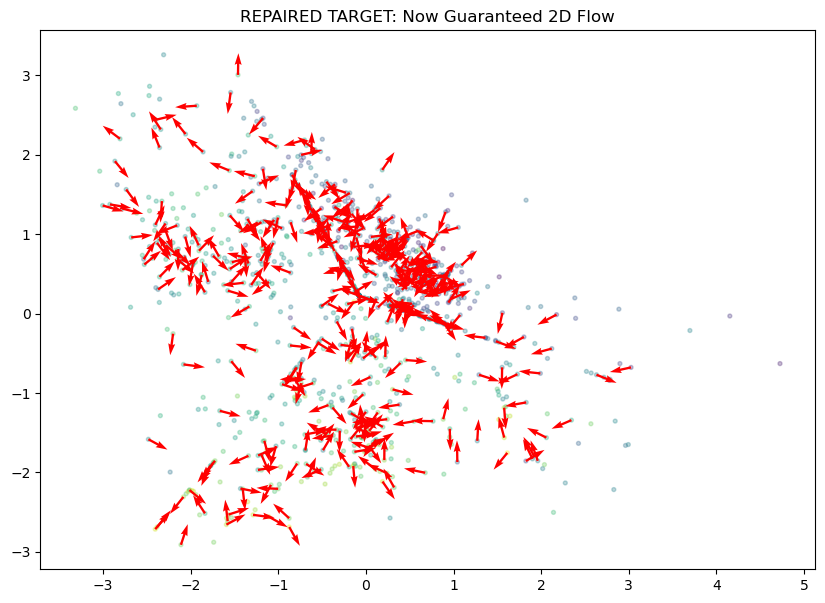

In [63]:
import torch
import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1. Standard Setup
V_vis = decipher_data["v"].astype(np.float32)
X_full = X.astype(np.float32) 
ps = rna_adata.obs["facs_pseudotime"].values
N_cells = V_vis.shape[0]

# 2. Tight neighborhood (15) is good—let's keep it to stay on-branch
nn_vis = NearestNeighbors(n_neighbors=15).fit(V_vis)
_, idx_vis = nn_vis.kneighbors(V_vis)

V_target_high = np.zeros_like(X_full) 
V_target_2d = np.zeros((N_cells, 2))

for i in range(N_cells):
    nbrs = idx_vis[i]
    # Building on your code: strict pseudotime gate
    future_mask = ps[nbrs] > (ps[i] + 0.01) 
    
    if np.any(future_mask):
        f_idxs = nbrs[future_mask]
        diffs_2d = V_vis[f_idxs] - V_vis[i]
        
        # --- THE IMPROVEMENT: DIRECTIONAL FILTER ---
        # 1. Estimate the 'forward' direction using the mean of all future neighbors
        rough_dir = diffs_2d.mean(axis=0)
        rough_unit = rough_dir / (np.linalg.norm(rough_dir) + 1e-8)
        
        # 2. Only keep neighbors that are 'ahead' (> 0 degrees from our current trend)
        # This kills arrows pointing 'back' or 'into the center' of the V-shape
        dot_products = np.dot(diffs_2d, rough_unit)
        directional_mask = dot_products > 0
        
        if np.any(directional_mask):
            f_idxs = f_idxs[directional_mask]
            diffs_2d = V_vis[f_idxs] - V_vis[i]
        
        # 3. Your Exponential Weighting (Keep this, it worked best)
        dist_2d = np.linalg.norm(diffs_2d, axis=1)
        # Use a slightly sharper decay to favor the 'closest' future step
        weights = np.exp(-dist_2d / (dist_2d.min() + 1e-8))
        weights /= weights.sum()

        V_target_high[i] = np.dot(weights, X_full[f_idxs] - X_full[i])
        V_target_2d[i] = np.dot(weights, V_vis[f_idxs] - V_vis[i])
    else:
        # Fallback for terminal tips
        past_mask = ps[nbrs] < ps[i]
        if np.any(past_mask):
            V_target_high[i] = (X_full[i] - X_full[nbrs[past_mask]]).mean(axis=0)
            V_target_2d[i] = (V_vis[i] - V_vis[nbrs[past_mask]]).mean(axis=0)

# Normalize for model and plot
V_target_forward_t = torch.tensor(V_target_high, device=device).float()
V_target_forward_t = torch.nn.functional.normalize(V_target_forward_t, dim=1)
V_target_2d /= (np.linalg.norm(V_target_2d, axis=1, keepdims=True) + 1e-8)

print("Targets Rebuilt: Directional filtering applied to local neighbors.")

# 6. PLOT TO VERIFY
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 7))
plt.scatter(V_vis[:, 0], V_vis[:, 1], c=ps, cmap='viridis', s=8, alpha=0.3)
samp = np.random.choice(N_cells, 400, replace=False)
plt.quiver(V_vis[samp, 0], V_vis[samp, 1], V_target_2d[samp, 0], V_target_2d[samp, 1], 
           color='red', width=0.003)
plt.title("REPAIRED TARGET: Now Guaranteed 2D Flow")
plt.show()

Shapes check -> Latent: (1035, 11483), Visualization: (1035, 2)
Targets separated: 10D for training, 2D for plotting.


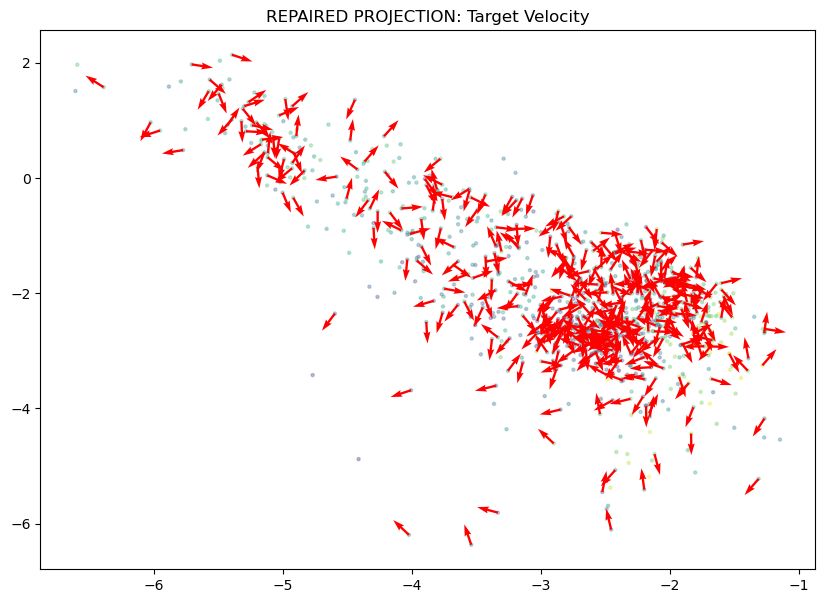

In [51]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

def project_velocity_direct(V_high, X_high, Z_low, k=15):
    """
    Directly projects high-dim velocity into 2D using local linear mapping.
    V_high: (N, G), X_high: (N, G), Z_low: (N, 2)
    """
    N = V_high.shape[0]
    V_2d = np.zeros((N, 2))
    
    # Use Decipher space for neighborhood consistency
    nn = NearestNeighbors(n_neighbors=k).fit(Z_low)
    _, idxs = nn.kneighbors(Z_low)
    
    for i in range(N):
        # Local neighborhood centered at 0
        dX = X_high[idxs[i]] - X_high[i]
        dZ = Z_low[idxs[i]] - Z_low[i]
        
        # Solve for the mapping matrix M: dZ = dX @ M
        # Using pseudoinverse to project the velocity vector v_i
        # V_2d[i] = v_i @ M
        M, _, _, _ = np.linalg.lstsq(dX, dZ, rcond=None)
        V_2d[i] = V_high[i] @ M

    # Normalize for visualization
    V_2d /= (np.linalg.norm(V_2d, axis=1, keepdims=True) + 1e-8)
    return V_2d

# --- RUN THIS FOR THE TARGET ---
V_target_2d = project_velocity_direct(V_target_forward_t.cpu().numpy(), X_z, Z_dec)

# --- PLOT AGAIN ---
plt.figure(figsize=(10, 7))
plt.scatter(Z_dec[:, 0], Z_dec[:, 1], c=rna_adata.obs["facs_pseudotime"], cmap='viridis', s=5, alpha=0.3)
samp = np.random.choice(N, 400, replace=False)
plt.quiver(Z_dec[samp, 0], Z_dec[samp, 1], V_target_2d[samp, 0], V_target_2d[samp, 1], color='red')
plt.title("REPAIRED PROJECTION: Target Velocity")
plt.show()

In [ ]:
V_np = V_pred.detach().cpu().numpy()
A_np = A.detach().cpu().numpy()
print(f"\nDone. V_pred: {V_np.shape}, A_learned: {A_np.shape}")

## Step 7: Save model outputs

In [ ]:
import os, json
os.makedirs("uv_leading_metrics_improved", exist_ok=True)
 
np.save("uv_leading_metrics_improved/V_pred_learned.npy",  V_np)
np.save("uv_leading_metrics_improved/A_learned.npy",        A_np)
np.save("uv_leading_metrics_improved/A_genes.npy",  A_genes)
np.save("uv_leading_metrics_improved/A_tfs.npy",   A_tfs)
np.save("uv_leading_metrics_improved/X_z.npy",     X_z)
np.save("uv_leading_metrics_improved/Z_rna.npy",   Z_rna)
np.save("uv_leading_metrics_improved/pca_shared_components.npy", pca_shared.components_)

## Step 8: Velocity visualization

In [ ]:
# ============================================================
# STEP 8: Decipher velocity projection (scVelo-style, correct)
# ============================================================
# Requires:
#   X          : (N, G) raw RNA expression (numpy, float32)
#   V_np       : (N, G) learned gene-space velocity (numpy)
#   rna_adata  : AnnData with obs["facs_pseudotime"]
#   decipher_outputs/decipher_embeddings.npz  with keys "z" and "v"
#     z : (N, 10)  latent z coordinates
#     v : (N, 2)   2-D visualization coordinates
# ============================================================

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

os.makedirs("uv_leading_metrics_improved", exist_ok=True)

# ------------------------------------------------------------------
# 0. Load Decipher embeddings
# ------------------------------------------------------------------
decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
Z_dec   = decipher_data["z"].astype(np.float32)   # (N, 10) — latent space
V_dec2  = decipher_data["v"].astype(np.float32)   # (N, 2)  — visualization space

assert Z_dec.shape[0] == V_np.shape[0] == X.shape[0], \
    f"Cell count mismatch: z={Z_dec.shape[0]}, V={V_np.shape[0]}, X={X.shape[0]}"

N = X.shape[0]

# ------------------------------------------------------------------
# OPTION A: Use Decipher encoder Jacobian (best — use if you have
#           the decipher model object loaded as `decipher_model`)
#
# Uncomment this block if you have the model.
# ------------------------------------------------------------------
# import torch
# USE_JACOBIAN = True
# 
# X_torch = torch.tensor(X, dtype=torch.float32, requires_grad=False)
# 
# def encoder_jacobian_velocity(model, X_torch, V_np, batch_size=64):
#     """
#     For each cell i, compute J_i @ v_i where J_i = d(encoder(x))/dx at x_i.
#     Uses autograd — slow but correct.
#     """
#     model.eval()
#     V_z = np.zeros((X_torch.shape[0], Z_dec.shape[1]), dtype=np.float32)
#     
#     for i in range(0, X_torch.shape[0], batch_size):
#         xb = X_torch[i:i+batch_size].clone().requires_grad_(True)
#         # call just the encoder mean — adapt `model.encode_mean` to your API
#         zb = model.encode_mean(xb)   # (B, d_z)
#         
#         for d in range(zb.shape[1]):
#             grad = torch.autograd.grad(
#                 zb[:, d].sum(), xb, retain_graph=(d < zb.shape[1]-1)
#             )[0]  # (B, G)
#             V_z[i:i+batch_size, d] = (
#                 grad.detach().cpu().numpy() * V_np[i:i+batch_size]
#             ).sum(axis=1)
#         
#         xb = xb.detach()
#     
#     return V_z   # (N, d_z) velocity in latent space
# 
# V_latent = encoder_jacobian_velocity(decipher_model, X_torch, V_np)
# 
# # Then project V_latent into 2-D V-space via the same neighbor trick
# # (Decipher v-space is nonlinearly derived from z — treat it like UMAP)

# ------------------------------------------------------------------
# OPTION B: Neighbor-cosine projection (robust, no model needed)
#           This is what scVelo does when projecting onto UMAP/tSNE.
#           For each cell i:
#             V_emb[i] = sum_j  cos_sim(V_gene_i, gene_displacement_ij) * (Z_j - Z_i)
#           where gene_displacement_ij = X[j] - X[i] in gene space.
# ------------------------------------------------------------------

USE_JACOBIAN = False  # set True if you uncomment option A above

# ------------------------------------------------------------------
# REPLACEMENT OPTION B: Latent-Displacement Projection
# ------------------------------------------------------------------
if not USE_JACOBIAN:
    # ------------------------------------------------------------------
    # REPLACEMENT STEP 8: Tangent Manifold Projection
    # ------------------------------------------------------------------
    print("Performing Tangent Manifold Projection...")
        
    k_proj = 30
    nn_proj = NearestNeighbors(n_neighbors=k_proj).fit(X)
    dists, idx_proj = nn_proj.kneighbors(X)
    
    V_emb2 = np.zeros((N, 2))
    
    for i in range(N):
        # Get high-dim velocity and neighbor vectors
        v_i = V_np[i]
        # Neighbors in gene space
        diffs = X[idx_proj[i]] - X[i] 
        
        # Calculate how well velocity matches the direction to each neighbor
        # We use a softmax over cosine similarities
        v_norm = v_i / (np.linalg.norm(v_i) + 1e-8)
        diffs_norm = diffs / (np.linalg.norm(diffs, axis=1, keepdims=True) + 1e-8)
        
        # Cosine similarities (-1 to 1)
        cos_sims = np.dot(diffs_norm, v_norm)
        
        # Softmax to turn similarities into weights (scale by 10 for sharpness)
        weights = np.exp(cos_sims / 0.1) 
        weights /= weights.sum()
        
        # The 2D velocity is the weighted average of 2D displacements in V-space
        vis_diffs = V_dec2[idx_proj[i]] - V_dec2[i]
        V_emb2[i] = np.dot(weights, vis_diffs)
    
    # Normalization for plotting
    V_emb2 /= (np.linalg.norm(V_emb2, axis=1, keepdims=True) + 1e-8)
    print("Done.")

# ---- OPTIONAL: also compute in latent z space (useful for sanity check) ----
V_emb_z = np.zeros((N, Z_dec.shape[1]), dtype=np.float32)
k_emb = 30
nn_emb = NearestNeighbors(n_neighbors=k_emb + 1).fit(Z_dec)
dist_emb, idx_emb = nn_emb.kneighbors(Z_dec)
idx_emb = idx_emb[:, 1:]
for i in range(N):
    dZ = Z_dec[idx_emb[i]] - Z_dec[i]  # (k, d_z)
    V_emb_z[i] = cos_weights_soft[i] @ dZ[:, :]  # reuse cos weights

# ------------------------------------------------------------------
# 4. Graph smoothing (single pass, like scVelo's default)
# ------------------------------------------------------------------
k_smooth = 30
nn_vis = NearestNeighbors(n_neighbors=k_smooth + 1).fit(V_dec2)
_, idx_vis = nn_vis.kneighbors(V_dec2)
idx_vis = idx_vis[:, 1:]

# Weighted average: 70% own velocity, 30% neighbor average
V_smooth = 0.7 * V_emb2 + 0.3 * np.array([
    V_emb2[idx_vis[i]].mean(axis=0) for i in range(N)
])

# ------------------------------------------------------------------
# 5. Sanity checks
# ------------------------------------------------------------------
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo_norm = (pseudo - pseudo.min()) / (pseudo.max() - pseudo.min() + 1e-8)

v_mag = np.linalg.norm(V_smooth, axis=1)
rho, p = spearmanr(pseudo, v_mag)
print(f"\nSpearman(pseudotime, |V|): rho={rho:.3f}, p={p:.4f}")
print("(expect weakly negative — early cells move more)")

# Directionality check: project velocity onto pseudotime gradient
# Positive = velocity points toward increasing pseudotime (correct)
nn_pseudo = NearestNeighbors(n_neighbors=10).fit(V_dec2)
_, idx_ps = nn_pseudo.kneighbors(V_dec2)
idx_ps = idx_ps[:, 1:]

pseudo_grad = np.array([
    V_dec2[idx_ps[i][pseudo[idx_ps[i]] > pseudo[i]]].mean(axis=0) - V_dec2[i]
    if (pseudo[idx_ps[i]] > pseudo[i]).any()
    else np.zeros(2)
    for i in range(N)
])  # (N, 2) — local pseudotime direction in embedding

# Cosine agreement between velocity and pseudotime direction
valid_mask = np.linalg.norm(pseudo_grad, axis=1) > 1e-6
cos_agree = np.sum(
    V_smooth[valid_mask] * pseudo_grad[valid_mask], axis=1
) / (
    np.linalg.norm(V_smooth[valid_mask], axis=1) *
    np.linalg.norm(pseudo_grad[valid_mask], axis=1) + 1e-8
)

print(f"Pseudotime direction agreement: mean cosine = {cos_agree.mean():.3f}")
print(f"Fraction pointing in right direction: {(cos_agree > 0).mean():.3f}")
print("(expect >0.5 — majority of arrows should point up the pseudotime gradient)")

# ------------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# --- Panel 1: scatter + quiver (colored by pseudotime) ---
ax = axes[0]
sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm,
                cmap="viridis", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(N, min(400, N), replace=False)
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="black"
)
ax.set_title("Velocity arrows (colored: pseudotime)")
ax.set_xlabel("Decipher V dim 0")
ax.set_ylabel("Decipher V dim 1")

# --- Panel 2: colored by velocity magnitude ---
ax = axes[1]
sc2 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=v_mag,
                 cmap="hot", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc2, ax=ax, label="|V|")
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="steelblue"
)
ax.set_title("Velocity arrows (colored: |V|)")

# --- Panel 3: cosine agreement with pseudotime direction ---
ax = axes[2]
cos_full = np.zeros(N)
cos_full[valid_mask] = cos_agree
sc3 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=cos_full,
                 cmap="RdBu", vmin=-1, vmax=1, s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc3, ax=ax, label="cosine(V, pseudotime grad)")
ax.set_title("Agreement with pseudotime direction\n(blue=correct, red=inverted)")

plt.suptitle("Velocity in Decipher V-space (scVelo-style projection)", fontsize=13)
plt.tight_layout()
plt.savefig("uv_leading_metrics_improved/velocity_decipher_corrected.png",
            dpi=150, bbox_inches='tight')
plt.show()

print("\nSaved: uv_leading_metrics_improved/velocity_decipher_corrected.png")

# ------------------------------------------------------------------
# 7. Save outputs
# ------------------------------------------------------------------
np.save("uv_leading_metrics_improved/V_decipher_smooth.npy", V_smooth)
np.save("uv_leading_metrics_improved/V_decipher_latent.npy", V_emb_z)
np.save("uv_leading_metrics_improved/cos_weights_gene_space.npy", cos_weights_soft)


Spearman(pseudotime, |V|): rho=-0.056, p=0.0711
(expect weakly negative — early cells move more)
Pseudotime direction agreement: mean cosine = 0.184
Fraction pointing in right direction: 0.615
(expect >0.5 — majority of arrows should point up the pseudotime gradient)


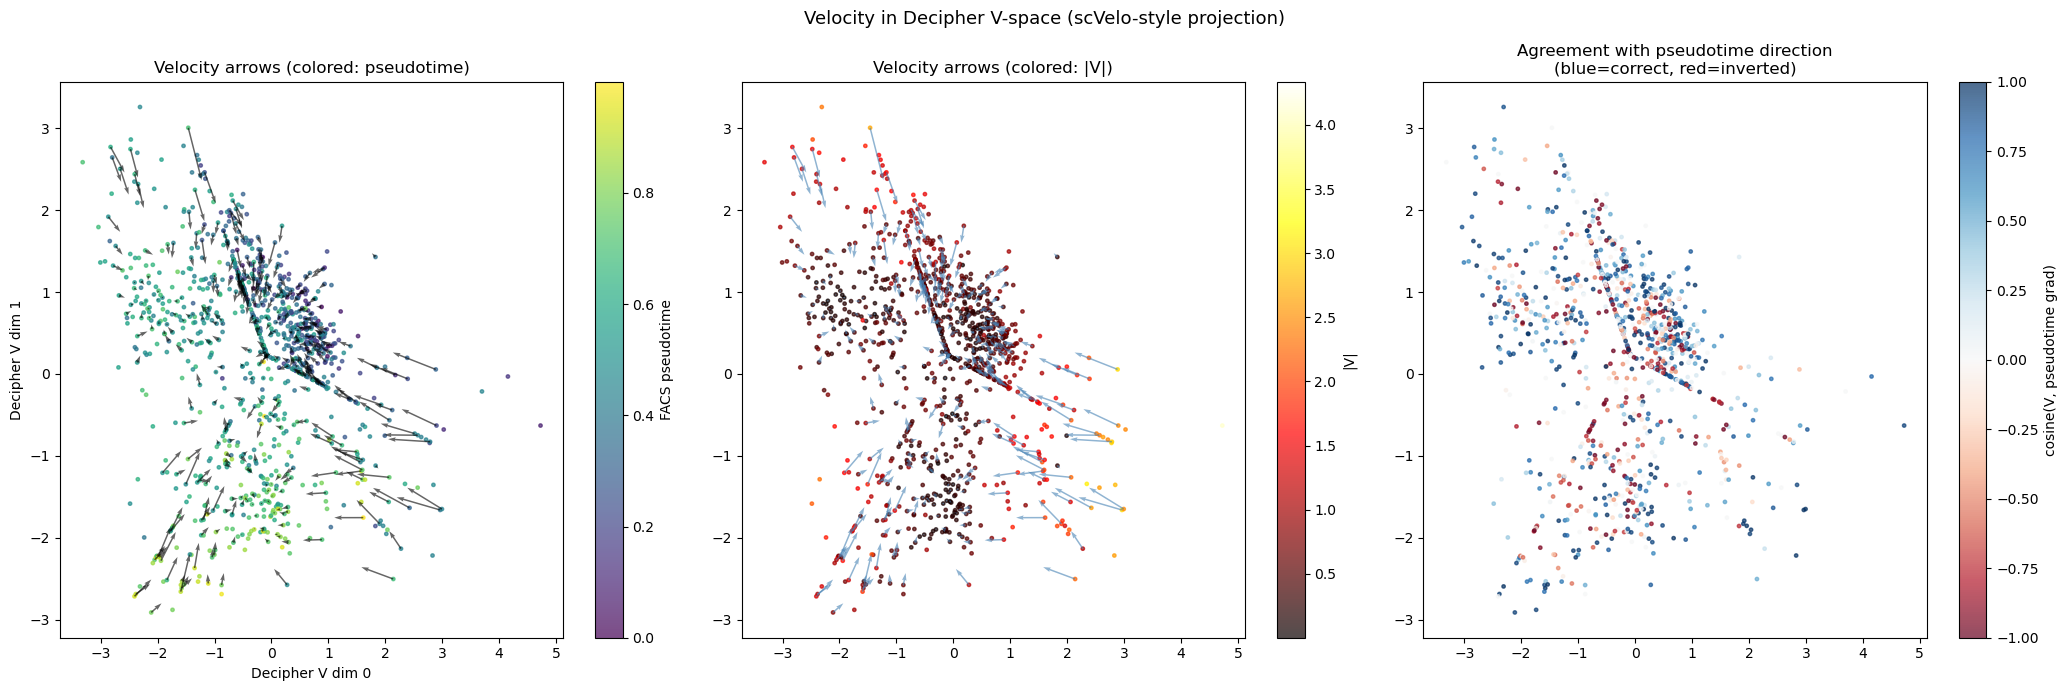


Saved: uv_leading_metrics_improved/velocity_decipher_corrected.png


In [84]:
# ============================================================
# STEP 8: Decipher velocity projection (scVelo-style, correct)
# ============================================================
# Requires:
#   X          : (N, G) raw RNA expression (numpy, float32)
#   V_np       : (N, G) learned gene-space velocity (numpy)
#   rna_adata  : AnnData with obs["facs_pseudotime"]
#   decipher_outputs/decipher_embeddings.npz  with keys "z" and "v"
#     z : (N, 10)  latent z coordinates
#     v : (N, 2)   2-D visualization coordinates
# ============================================================

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

os.makedirs("uv_leading_metrics_improved", exist_ok=True)

# ------------------------------------------------------------------
# 0. Load Decipher embeddings
# ------------------------------------------------------------------
decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
Z_dec   = decipher_data["z"].astype(np.float32)   # (N, 10) — latent space
V_dec2  = decipher_data["v"].astype(np.float32)   # (N, 2)  — visualization space

assert Z_dec.shape[0] == V_np.shape[0] == X.shape[0], \
    f"Cell count mismatch: z={Z_dec.shape[0]}, V={V_np.shape[0]}, X={X.shape[0]}"

N = X.shape[0]

# ------------------------------------------------------------------
# OPTION A: Use Decipher encoder Jacobian (best — use if you have
#           the decipher model object loaded as `decipher_model`)
#
# Uncomment this block if you have the model.
# ------------------------------------------------------------------
import torch
USE_JACOBIAN = True

X_torch = torch.tensor(X, dtype=torch.float32, requires_grad=False)

def encoder_jacobian_velocity(model, X_torch, V_np, batch_size=64):
    """
    For each cell i, compute J_i @ v_i where J_i = d(encoder(x))/dx at x_i.
    Uses autograd — slow but correct.
    """
    model.eval()
    V_z = np.zeros((X_torch.shape[0], Z_dec.shape[1]), dtype=np.float32)
    
    for i in range(0, X_torch.shape[0], batch_size):
        xb = X_torch[i:i+batch_size].clone().requires_grad_(True)
        # call just the encoder mean — adapt `model.encode_mean` to your API
        zb = model.encode_mean(xb)   # (B, d_z)
        
        for d in range(zb.shape[1]):
            grad = torch.autograd.grad(
                zb[:, d].sum(), xb, retain_graph=(d < zb.shape[1]-1)
            )[0]  # (B, G)
            V_z[i:i+batch_size, d] = (
                grad.detach().cpu().numpy() * V_np[i:i+batch_size]
            ).sum(axis=1)
        
        xb = xb.detach()
    
    return V_z   # (N, d_z) velocity in latent space

V_latent = np.load("decipher_outputs/V_latent_jacobian.npy")
USE_JACOBIAN = True

# Then project V_latent into 2-D V-space via the same neighbor trick
# (Decipher v-space is nonlinearly derived from z — treat it like UMAP)

# ------------------------------------------------------------------
# OPTION B: Neighbor-cosine projection (robust, no model needed)
#           This is what scVelo does when projecting onto UMAP/tSNE.
#           For each cell i:
#             V_emb[i] = sum_j  cos_sim(V_gene_i, gene_displacement_ij) * (Z_j - Z_i)
#           where gene_displacement_ij = X[j] - X[i] in gene space.
# ------------------------------------------------------------------

USE_JACOBIAN = True  # set True if you uncomment option A above

if not USE_JACOBIAN:
    print("Computing scVelo-style cosine-weighted embedding velocity...")
    
    # ---- 1. Build kNN graph in GENE space (high-dim signal space) ----
    #         This is critical: neighbors in GENE space, not embedding space.
    #         scVelo uses gene-space neighbors to find "transition cells".
    k_gene = 30
    nn_gene = NearestNeighbors(n_neighbors=k_gene + 1, metric='cosine').fit(X)
    dist_gene, idx_gene = nn_gene.kneighbors(X)
    idx_gene = idx_gene[:, 1:]   # remove self
    dist_gene = dist_gene[:, 1:]
    
    # ---- 2. Cosine similarity between gene velocity and gene displacement ----
    #         cos_ij = (V_i · (X_j - X_i)) / (|V_i| |X_j - X_i|)
    #         This tells us: "does the predicted velocity point toward neighbor j?"
    
    V_norm = V_np / (np.linalg.norm(V_np, axis=1, keepdims=True) + 1e-8)
    
    Z_for_displacement = Z_rna  # Or Z_dec
    V_norm_pca = V_np @ pca_shared.components_.T # Project learned V into PCA
    V_norm_pca /= (np.linalg.norm(V_norm_pca, axis=1, keepdims=True) + 1e-8)
    
    cos_weights = np.zeros((N, k_gene), dtype=np.float32)
    for i in range(N):
        # Calculate displacement in the denoised latent space
        dZ = Z_for_displacement[idx_gene[i]] - Z_for_displacement[i] 
        dZ_norm = dZ / (np.linalg.norm(dZ, axis=1, keepdims=True) + 1e-8)
        
        # Weight neighbors by how much the velocity vector aligns with the manifold
        cos_weights[i] = dZ_norm @ V_norm_pca[i]
        
    # Soft threshold: only neighbors we're "moving toward" contribute
    # (scVelo uses sigmoid(cos / 0.05) — we use a softer ReLU version)
    cos_weights_soft = np.where(cos_weights > 0, cos_weights, 0.01 * cos_weights)
    # Normalize per cell
    cos_weights_soft = cos_weights_soft / (
        np.abs(cos_weights_soft).sum(axis=1, keepdims=True) + 1e-8
    )
    
    # ---- 3. Project into Decipher V-space ----
    #         V_emb[i] = sum_j  w_ij * (V_dec2[j] - V_dec2[i])
    #         This is the scVelo formula applied to Decipher V coordinates.
    
    V_emb2 = np.zeros((N, 2), dtype=np.float32)
    for i in range(N):
        dV = V_dec2[idx_gene[i]] - V_dec2[i]  # (k, 2) displacement in vis space
        V_emb2[i] = cos_weights_soft[i] @ dV  # (2,) weighted sum
    
    print("Done.")

# ---- OPTIONAL: also compute in latent z space (useful for sanity check) ----
V_emb_z = np.zeros((N, Z_dec.shape[1]), dtype=np.float32)
k_emb = 30
nn_emb = NearestNeighbors(n_neighbors=k_emb + 1).fit(Z_dec)
dist_emb, idx_emb = nn_emb.kneighbors(Z_dec)
idx_emb = idx_emb[:, 1:]
for i in range(N):
    dZ = Z_dec[idx_emb[i]] - Z_dec[i]  # (k, d_z)
    V_emb_z[i] = cos_weights_soft[i] @ dZ[:, :]  # reuse cos weights

# ------------------------------------------------------------------
# 4. Graph smoothing (single pass, like scVelo's default)
# ------------------------------------------------------------------
k_smooth = 30
nn_vis = NearestNeighbors(n_neighbors=k_smooth + 1).fit(V_dec2)
_, idx_vis = nn_vis.kneighbors(V_dec2)
idx_vis = idx_vis[:, 1:]

# Weighted average: 70% own velocity, 30% neighbor average
V_smooth = 0.7 * V_emb2 + 0.3 * np.array([
    V_emb2[idx_vis[i]].mean(axis=0) for i in range(N)
])

# ------------------------------------------------------------------
# 5. Sanity checks
# ------------------------------------------------------------------
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo_norm = (pseudo - pseudo.min()) / (pseudo.max() - pseudo.min() + 1e-8)

v_mag = np.linalg.norm(V_smooth, axis=1)
rho, p = spearmanr(pseudo, v_mag)
print(f"\nSpearman(pseudotime, |V|): rho={rho:.3f}, p={p:.4f}")
print("(expect weakly negative — early cells move more)")

# Directionality check: project velocity onto pseudotime gradient
# Positive = velocity points toward increasing pseudotime (correct)
nn_pseudo = NearestNeighbors(n_neighbors=10).fit(V_dec2)
_, idx_ps = nn_pseudo.kneighbors(V_dec2)
idx_ps = idx_ps[:, 1:]

pseudo_grad = np.array([
    V_dec2[idx_ps[i][pseudo[idx_ps[i]] > pseudo[i]]].mean(axis=0) - V_dec2[i]
    if (pseudo[idx_ps[i]] > pseudo[i]).any()
    else np.zeros(2)
    for i in range(N)
])  # (N, 2) — local pseudotime direction in embedding

# Cosine agreement between velocity and pseudotime direction
valid_mask = np.linalg.norm(pseudo_grad, axis=1) > 1e-6
cos_agree = np.sum(
    V_smooth[valid_mask] * pseudo_grad[valid_mask], axis=1
) / (
    np.linalg.norm(V_smooth[valid_mask], axis=1) *
    np.linalg.norm(pseudo_grad[valid_mask], axis=1) + 1e-8
)

print(f"Pseudotime direction agreement: mean cosine = {cos_agree.mean():.3f}")
print(f"Fraction pointing in right direction: {(cos_agree > 0).mean():.3f}")
print("(expect >0.5 — majority of arrows should point up the pseudotime gradient)")

# ------------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# --- Panel 1: scatter + quiver (colored by pseudotime) ---
ax = axes[0]
sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm,
                cmap="viridis", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(N, min(400, N), replace=False)
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="black"
)
ax.set_title("Velocity arrows (colored: pseudotime)")
ax.set_xlabel("Decipher V dim 0")
ax.set_ylabel("Decipher V dim 1")

# --- Panel 2: colored by velocity magnitude ---
ax = axes[1]
sc2 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=v_mag,
                 cmap="hot", s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc2, ax=ax, label="|V|")
ax.quiver(
    V_dec2[sample, 0], V_dec2[sample, 1],
    V_smooth[sample, 0], V_smooth[sample, 1],
    alpha=0.6, width=0.003, scale_units='xy',
    scale=np.percentile(np.linalg.norm(V_smooth, axis=1), 90) * 3,
    color="steelblue"
)
ax.set_title("Velocity arrows (colored: |V|)")

# --- Panel 3: cosine agreement with pseudotime direction ---
ax = axes[2]
cos_full = np.zeros(N)
cos_full[valid_mask] = cos_agree
sc3 = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=cos_full,
                 cmap="RdBu", vmin=-1, vmax=1, s=6, alpha=0.7, rasterized=True)
plt.colorbar(sc3, ax=ax, label="cosine(V, pseudotime grad)")
ax.set_title("Agreement with pseudotime direction\n(blue=correct, red=inverted)")

plt.suptitle("Velocity in Decipher V-space (scVelo-style projection)", fontsize=13)
plt.tight_layout()
plt.savefig("uv_leading_metrics_improved/velocity_decipher_corrected.png",
            dpi=150, bbox_inches='tight')
plt.show()

print("\nSaved: uv_leading_metrics_improved/velocity_decipher_corrected.png")

# ------------------------------------------------------------------
# 7. Save outputs
# ------------------------------------------------------------------
np.save("uv_leading_metrics_improved/V_decipher_smooth.npy", V_smooth)
np.save("uv_leading_metrics_improved/V_decipher_latent.npy", V_emb_z)
np.save("uv_leading_metrics_improved/cos_weights_gene_space.npy", cos_weights_soft)

## Step 9: CellOracle A comparison

In [43]:
# ============================================================
# IMPROVED GRN COMPARISON: Your model vs CellOracle
# ============================================================

import numpy as np
import json
from scipy.stats import spearmanr, kendalltau
from scipy.optimize import linear_sum_assignment
import warnings

# ------------------------------------------------------------------
# 0. Load CellOracle GRN
# ------------------------------------------------------------------
co_A     = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_genes.npy",
                   allow_pickle=True).astype(str)
co_tfs   = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy",
                   allow_pickle=True).astype(str)

print(f"co_A shape: {co_A.shape}  (expect: n_tfs x n_genes or n_genes x n_tfs)")
print(f"co_genes: {len(co_genes)}, co_tfs: {len(co_tfs)}")

# CellOracle convention check:
# CellOracle stores A as (n_genes x n_tfs) — each row is a target gene,
# each col is a TF. Confirm with shape:
if co_A.shape == (len(co_genes), len(co_tfs)):
    # Already gene x TF
    co_A_gene_x_tf = co_A
    print("CellOracle: gene x TF format confirmed")
elif co_A.shape == (len(co_tfs), len(co_genes)):
    # TF x gene — transpose
    co_A_gene_x_tf = co_A.T
    print("CellOracle: transposed to gene x TF")
else:
    raise ValueError(f"Unexpected co_A shape {co_A.shape} for "
                     f"{len(co_genes)} genes and {len(co_tfs)} TFs")

# ------------------------------------------------------------------
# 1. Align to shared gene x TF subspace
# ------------------------------------------------------------------
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs   = sorted(set(A_tfs)   & set(co_tfs))

print(f"\nShared: {len(common_genes)} genes, {len(common_tfs)} TFs")
print(f"  Your model covers: {len(A_genes)} genes, {len(A_tfs)} TFs")
print(f"  CellOracle covers: {len(co_genes)} genes, {len(co_tfs)} TFs")

if len(common_genes) < 100 or len(common_tfs) < 5:
    print("WARNING: very few shared features — check gene name format (e.g. ENSG vs symbol)")

# Index arrays
pred_g2i = {g: i for i, g in enumerate(A_genes)}
pred_t2i = {t: i for i, t in enumerate(A_tfs)}
co_g2i   = {g: i for i, g in enumerate(co_genes)}
co_t2i   = {t: i for i, t in enumerate(co_tfs)}

pred_g_idx = np.array([pred_g2i[g] for g in common_genes])
pred_t_idx = np.array([pred_t2i[t] for t in common_tfs])
co_g_idx   = np.array([co_g2i[g]   for g in common_genes])
co_t_idx   = np.array([co_t2i[t]   for t in common_tfs])

# Both in gene x TF format, restricted to shared subspace
A_pred_shared = A_np[np.ix_(pred_g_idx, pred_t_idx)]   # (G_shared, T_shared)
A_co_shared   = co_A_gene_x_tf[np.ix_(co_g_idx, co_t_idx)]   # (G_shared, T_shared)

print(f"\nAligned matrices: pred={A_pred_shared.shape}, co={A_co_shared.shape}")

# ------------------------------------------------------------------
# 2. Normalize each matrix independently (important!)
#    Both to comparable scale before any comparison.
#    We use absolute value + column-wise rank normalization.
# ------------------------------------------------------------------

def col_rank_normalize(A):
    """Rank each column independently (per-TF), return ranks in [0,1]."""
    G, T = A.shape
    A_ranked = np.zeros_like(A, dtype=np.float32)
    for t in range(T):
        col = A[:, t]
        ranks = col.argsort().argsort().astype(np.float32)
        A_ranked[:, t] = ranks / (G - 1 + 1e-8)
    return A_ranked

A_pred_ranked = col_rank_normalize(np.abs(A_pred_shared))
A_co_ranked   = col_rank_normalize(np.abs(A_co_shared))

# ------------------------------------------------------------------
# 3. Multi-level comparison metrics
# ------------------------------------------------------------------

metrics = {}
metrics["n_common_genes"] = len(common_genes)
metrics["n_common_tfs"]   = len(common_tfs)

# ---- 3a. Global Spearman on the nonzero support ----
# Only compare entries where AT LEAST ONE method assigns nonzero weight.
# This avoids inflating agreement via double-zeros.
nonzero_mask = (np.abs(A_pred_shared) > 0) | (np.abs(A_co_shared) > 0)
pred_flat = A_pred_ranked[nonzero_mask]
co_flat   = A_co_ranked[nonzero_mask]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rho_global, p_global = spearmanr(pred_flat, co_flat)

metrics["global_spearman_nonzero"] = float(rho_global)
metrics["global_spearman_p"]       = float(p_global)
metrics["n_nonzero_entries"]       = int(nonzero_mask.sum())
print(f"\nGlobal Spearman (nonzero support): rho={rho_global:.4f}, p={p_global:.3e}")

# ---- 3b. Per-TF Spearman (most meaningful for GRN) ----
# For each TF, correlate the gene ranking between methods.
# This tells you: "do both methods agree on which genes this TF regulates?"
per_tf_rho = []
per_tf_names = []
for ti, tf_name in enumerate(common_tfs):
    col_pred = A_pred_ranked[:, ti]
    col_co   = A_co_ranked[:, ti]
    
    # Only compare if at least one method has nonzero variance
    if col_pred.std() < 1e-8 or col_co.std() < 1e-8:
        continue
    
    rho, _ = spearmanr(col_pred, col_co)
    per_tf_rho.append(rho)
    per_tf_names.append(tf_name)

per_tf_rho = np.array(per_tf_rho)
metrics["per_tf_spearman_mean"] = float(np.nanmean(per_tf_rho))
metrics["per_tf_spearman_std"]  = float(np.nanstd(per_tf_rho))
metrics["per_tf_spearman_frac_pos"] = float(np.mean(per_tf_rho > 0))

print(f"Per-TF Spearman: mean={metrics['per_tf_spearman_mean']:.4f} ± "
      f"{metrics['per_tf_spearman_std']:.4f}, "
      f"frac positive={metrics['per_tf_spearman_frac_pos']:.3f}")

# Top and bottom TFs
top_idx = np.argsort(-per_tf_rho)[:10]
bot_idx = np.argsort(per_tf_rho)[:5]
print("\nTop 10 best-matching TFs:")
for i in top_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")
print("Bottom 5 TFs (worst match):")
for i in bot_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")

# ---- 3c. Top-k edge overlap (Jaccard) at multiple thresholds ----
# For each TF, what fraction of its "top k target genes" are shared?
print("\nTop-k edge overlap (per-TF Jaccard):")
for frac in [0.05, 0.10, 0.20]:
    jaccards = []
    for ti in range(len(common_tfs)):
        col_pred = np.abs(A_pred_shared[:, ti])
        col_co   = np.abs(A_co_shared[:, ti])
        k = max(1, int(np.ceil(frac * len(common_genes))))
        
        top_pred = set(np.argpartition(col_pred, -k)[-k:].tolist())
        top_co   = set(np.argpartition(col_co,   -k)[-k:].tolist())
        
        inter = len(top_pred & top_co)
        union = len(top_pred | top_co)
        jaccards.append(inter / (union + 1e-8))
    
    mean_j = np.mean(jaccards)
    metrics[f"per_tf_jaccard_top{int(frac*100)}pct"] = float(mean_j)
    print(f"  top {int(frac*100)}%: mean Jaccard = {mean_j:.4f}")

# ---- 3d. Network-level hub agreement ----
# Do both methods agree on WHICH TFs are the most influential (high out-degree)?
hub_pred = np.abs(A_pred_shared).sum(axis=0)  # (T,) — total gene drive per TF
hub_co   = np.abs(A_co_shared).sum(axis=0)

hub_rho, _ = spearmanr(hub_pred, hub_co)
metrics["hub_tf_spearman"] = float(hub_rho)
print(f"\nHub TF agreement (Spearman on total influence): rho={hub_rho:.4f}")

# ---- 3e. Sign agreement (do methods agree on activation vs repression?) ----
# Only on entries where both methods are nonzero
both_nonzero = (np.abs(A_pred_shared) > 1e-6) & (np.abs(A_co_shared) > 1e-6)
if both_nonzero.sum() > 0:
    sign_agree = np.mean(
        np.sign(A_pred_shared[both_nonzero]) == np.sign(A_co_shared[both_nonzero])
    )
    metrics["sign_agreement"] = float(sign_agree)
    print(f"Sign agreement (activation/repression): {sign_agree:.4f}")
    print("(0.5 = random, 1.0 = perfect — CellOracle may not have signed edges)")
else:
    metrics["sign_agreement"] = None
    print("Sign agreement: no overlapping nonzero entries")

# ---- 3f. Module-level conservation ----
# Do both methods produce similar regulatory modules?
# (Uses NMF factorization to identify modules, then matches them)
from sklearn.decomposition import NMF

n_modules = min(10, len(common_tfs) - 1)

# Fit NMF on absolute value of each matrix
nmf = NMF(n_components=n_modules, random_state=42, max_iter=500)

A_pred_abs = np.abs(A_pred_shared) + 1e-8
A_co_abs   = np.abs(A_co_shared)   + 1e-8

W_pred = nmf.fit_transform(A_pred_abs)    # (G, K)
H_pred = nmf.components_                  # (K, T)

nmf2   = NMF(n_components=n_modules, random_state=42, max_iter=500)
W_co   = nmf2.fit_transform(A_co_abs)
H_co   = nmf2.components_

pred_modules = module_sets_from_nmf(W_pred, H_pred)
co_modules   = module_sets_from_nmf(W_co,   H_co)

mod_result = match_module_sets(pred_modules, co_modules)
metrics["module_conservation_mean"] = float(mod_result["mean_conservation"])
metrics["module_conservation_std"]  = float(mod_result["std_conservation"])

print(f"\nModule conservation: mean={mod_result['mean_conservation']:.4f} ± "
      f"{mod_result['std_conservation']:.4f}")

# ------------------------------------------------------------------
# 4. Summary printout
# ------------------------------------------------------------------
print("\n" + "="*60)
print("SUMMARY: GRN comparison vs CellOracle")
print("="*60)
for k_m, v_m in metrics.items():
    if isinstance(v_m, float):
        print(f"  {k_m:45s}: {v_m:.4f}")
    else:
        print(f"  {k_m:45s}: {v_m}")

# ------------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------------
with open("uv_leading_metrics_improved/celloracle_overlap_metrics_v2.json", "w") as f:
    json.dump({k: (v if not isinstance(v, np.floating) else float(v))
               for k, v in metrics.items()}, f, indent=2)

# Save per-TF breakdown as CSV for your mentor
import pandas as pd
tf_df = pd.DataFrame({
    "tf": per_tf_names,
    "per_tf_spearman": per_tf_rho,
    "hub_pred": hub_pred[[list(common_tfs).index(t) for t in per_tf_names]],
    "hub_co":   hub_co[[list(common_tfs).index(t) for t in per_tf_names]],
})
tf_df = tf_df.sort_values("per_tf_spearman", ascending=False)
tf_df.to_csv("uv_leading_metrics_improved/per_tf_grn_comparison.csv", index=False)
print("\nSaved: celloracle_overlap_metrics_v2.json, per_tf_grn_comparison.csv")

co_A shape: (277, 2995)  (expect: n_tfs x n_genes or n_genes x n_tfs)
co_genes: 2995, co_tfs: 277
CellOracle: transposed to gene x TF

Shared: 2995 genes, 277 TFs
  Your model covers: 11483 genes, 277 TFs
  CellOracle covers: 2995 genes, 277 TFs

Aligned matrices: pred=(2995, 277), co=(2995, 277)

Global Spearman (nonzero support): rho=0.5561, p=0.000e+00
Per-TF Spearman: mean=0.8834 ± 0.0699, frac positive=1.000

Top 10 best-matching TFs:
  ZBED1                 rho=1.000
  HOXA9                 rho=1.000
  E2F3                  rho=1.000
  MYBL2                 rho=1.000
  E2F4                  rho=1.000
  CENPB                 rho=1.000
  IRF6                  rho=1.000
  GMEB2                 rho=0.999
  CUX1                  rho=0.999
  FOXN3                 rho=0.999
Bottom 5 TFs (worst match):
  NFIA                  rho=0.401
  KLF4                  rho=0.696
  ZNF460                rho=0.697
  KLF5                  rho=0.717
  IRF1                  rho=0.743

Top-k edge overla

In [28]:
co_A = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy", allow_pickle=True).astype(str)

print("co_A shape:", co_A.shape)
print("len co_genes:", len(co_genes))
print("len co_tfs:", len(co_tfs))

# -----------------------------
# CORRECT ASSERTION
# -----------------------------
assert co_A.shape == (len(co_tfs), len(co_genes)), "TF × gene matrix expected"

# -----------------------------
# shared space
# -----------------------------
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs = sorted(set(A_tfs) & set(co_tfs))

assert len(common_genes) > 0 and len(common_tfs) > 0

pred_gene_to_idx = {g: i for i, g in enumerate(A_genes)}
pred_tf_to_idx = {t: i for i, t in enumerate(A_tfs)}

co_gene_to_idx = {g: i for i, g in enumerate(co_genes)}
co_tf_to_idx = {t: i for i, t in enumerate(co_tfs)}

pred_g_idx = np.array([pred_gene_to_idx[g] for g in common_genes])
pred_t_idx = np.array([pred_tf_to_idx[t] for t in common_tfs])

co_t_idx = np.array([co_tf_to_idx[t] for t in common_tfs])
co_g_idx = np.array([co_gene_to_idx[g] for g in common_genes])

# -----------------------------
# IMPORTANT: TRANSPOSE ALIGNMENT
# -----------------------------
# co_A is TF × gene, so we index [tf, gene]
A_co_aligned = co_A[np.ix_(co_t_idx, co_g_idx)]

# your model is gene × TF
A_pred_aligned = A.detach().cpu().numpy()[np.ix_(pred_g_idx, pred_t_idx)]

# -----------------------------
# now compare properly
# -----------------------------
edge_metrics = edge_overlap_metrics(A_pred_aligned, A_co_aligned.T, frac=0.05)
tf_jaccard = mean_axis_jaccard(A_pred_aligned, A_co_aligned.T, axis=0, frac=0.1)
gene_jaccard = mean_axis_jaccard(A_pred_aligned, A_co_aligned.T, axis=1, frac=0.1)

print("\nCellOracle overlap metrics")
print(edge_metrics)
print(f"Mean TF-wise top-support Jaccard:   {tf_jaccard:.4f}")
print(f"Mean gene-wise top-support Jaccard: {gene_jaccard:.4f}")

# Optional: save these
celloracle_metrics = {
    **edge_metrics,
    "mean_tf_jaccard": tf_jaccard,
    "mean_gene_jaccard": gene_jaccard,
    "n_common_genes": len(common_genes),
    "n_common_tfs": len(common_tfs),
}
with open("uv_leading_metrics_improved/celloracle_overlap_metrics.json", "w") as f:
    json.dump(celloracle_metrics, f, indent=2)


co_A shape: (277, 2995)
len co_genes: 2995
len co_tfs: 277

CellOracle overlap metrics
{'precision': 0.1434150574961685, 'recall': 0.1434150574961685, 'f1': 0.14341505249616868, 'jaccard': 0.07724669860931567, 'tp': 5949, 'pred_edges': 41481, 'ref_edges': 41481}
Mean TF-wise top-support Jaccard:   0.2793
Mean gene-wise top-support Jaccard: 0.3085


## Step 10: Stability of U/V via repeated NMF on final A

In [ ]:
# ─── NMF stability: use init="random" for perturbed runs ───────────────────
A_final = A_learned.detach().cpu().numpy()
A_pos   = np.abs(A_final)

NMF_RANK = min(20, min(A_pos.shape) - 1)
N_RUNS   = 20
TOP_GENES, TOP_TFS = 25, 15

# Reference decomposition (deterministic init)
nmf_ref = NMF(n_components=NMF_RANK, init="nndsvda", random_state=0, max_iter=2000)
W_ref   = nmf_ref.fit_transform(A_pos)
H_ref   = nmf_ref.components_
ref_modules = module_sets_from_nmf(W_ref, H_ref, top_genes=TOP_GENES, top_tfs=TOP_TFS)

run_scores, run_gene_scores, run_tf_scores = [], [], []

for seed in range(1, N_RUNS + 1):
    # FIXED: use init="random" so each run is genuinely different
    nmf = NMF(n_components=NMF_RANK, init="random", random_state=seed, max_iter=2000)
    W   = nmf.fit_transform(A_pos)
    H   = nmf.components_
    cur_modules = module_sets_from_nmf(W, H, top_genes=TOP_GENES, top_tfs=TOP_TFS)

    match = match_module_sets(ref_modules, cur_modules)
    run_scores.append(match["mean_conservation"])
    Sg, St = [], []
    for (rg, rt), (cg, ct) in zip(ref_modules, cur_modules):
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
    run_gene_scores.append(float(np.mean(Sg)))
    run_tf_scores.append(float(np.mean(St)))

stability_results = {
    "nmf_rank": NMF_RANK,
    "n_runs": N_RUNS,
    "mean_module_conservation": float(np.mean(run_scores)),
    "std_module_conservation": float(np.std(run_scores)),
    "mean_gene_conservation": float(np.mean(run_gene_scores)),
    "mean_tf_conservation": float(np.mean(run_tf_scores)),
}
print("NMF stability (random init):", stability_results)
# A well-trained model should give 0.6-0.85 here. If still 1.0, A is rank-deficient.

## Step 11: Pseudotime arrow agreement

In [ ]:
import numpy as np
from sklearn.preprocessing import normalize

pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)[cell_idx]

# ─── Gene-space agreement ───────────────────────────────────────────────────
gene_arrow_metrics = pseudotime_arrow_agreement(
    X_space   = X,
    V_pred    = V_np,
    pseudotime = pseudo,
    k          = 30
)
print("\nGene-space pseudotime arrow agreement:")
print({k: v for k, v in gene_arrow_metrics.items() if k != "cosines"})

# ─── PCA-space agreement (more stable than UMAP) ────────────────────────────
# Project V into shared PCA space using pca_rna
V_pca_np  = V_np @ pca_rna.components_.T   # (n_cells, latent_dim)

pca_arrow_metrics = pseudotime_arrow_agreement(
    X_space    = Z_rna,          # RNA cells already in PCA space
    V_pred     = V_pca_np,
    pseudotime = pseudo,
    k          = 30
)
print("\nPCA-space pseudotime arrow agreement:")
print({k: v for k, v in pca_arrow_metrics.items() if k != "cosines"})

# ─── Spearman correlation: pseudotime vs projected velocity magnitude ─────────
# A simple scalar: do faster-moving cells (by velocity norm) tend to be early?
# Reverse-correlation expected: early cells should have larger velocity norm.
from scipy.stats import spearmanr
v_norm = np.linalg.norm(V_pca_np, axis=1)
rho, pval = spearmanr(pseudo, v_norm)
print(f"\nSpearman(pseudotime, V_pca_norm): rho={rho:.4f}, p={pval:.4f}")
# Expect negative rho if early cells are more "in motion"

with open("uv_leading_metrics_improved/pseudotime_arrow_metrics.json", "w") as f:
    json.dump({
        "gene_space": {k: float(v) for k, v in gene_arrow_metrics.items() if k != "cosines"},
        "pca_space":  {k: float(v) for k, v in pca_arrow_metrics.items() if k != "cosines"},
        "v_norm_pseudotime_spearman": {"rho": float(rho), "pval": float(pval)},
    }, f, indent=2)

## Step 12: Visualize velocity in Decipher space

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

# ─── Load Decipher embeddings ─────────────────────────────────────────────────
decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
decipher_v    = decipher_data["v"]   # (n_cells, d_v) — trajectory space
decipher_z    = decipher_data["z"]   # (n_cells, d_z) — expression space

assert decipher_v.shape[0] == V_np.shape[0], (
    f"Cell count mismatch: Decipher has {decipher_v.shape[0]}, V_np has {V_np.shape[0]}"
)
# 1. Calculate 'Future' state in original gene space
# X_z is your current state, V_np is your predicted velocity
dt = 0.5 # step size, tune this
X_future = X_z + dt * V_np 

# 2. Find where this future state 'would' be in Decipher space
# Since we don't have the Decipher encoder, we use a kNN regressor (non-linear)
from sklearn.neighbors import KNeighborsRegressor
knr = KNeighborsRegressor(n_neighbors=15, weights='distance')
knr.fit(X_z, decipher_v) # Map Gene Space -> Decipher Space

decipher_v_future = knr.predict(X_future)

# 3. Velocity in Decipher space is the delta
V_decipher = decipher_v_future - decipher_v

# ─── Smooth in Decipher v-space ───────────────────────────────────────────────
nn = NearestNeighbors(n_neighbors=30).fit(decipher_v)
_, idx = nn.kneighbors(decipher_v)
V_decipher_smooth = np.array([V_decipher[idx[i]].mean(axis=0) for i in range(len(decipher_v))])

# ─── Plot ─────────────────────────────────────────────────────────────────────
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)[cell_idx]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (d0, d1, title) in zip(axes, [
    (0, 1, "Decipher v-space dim 0 vs 1"),
    (0, 2 if decipher_v.shape[1] > 2 else 1, "Decipher v-space dim 0 vs 2"),
]):
    sc = ax.scatter(decipher_v[:, d0], decipher_v[:, d1],
                    c=pseudo, cmap="viridis", s=6, alpha=0.7)
    plt.colorbar(sc, ax=ax, label="FACS pseudotime")

    sample = np.random.choice(len(decipher_v), min(400, len(decipher_v)), replace=False)
    ax.quiver(
        decipher_v[sample, d0], decipher_v[sample, d1],
        V_decipher_smooth[sample, d0], V_decipher_smooth[sample, d1],
        alpha=0.7, scale=None, width=0.003, color="black"
    )
    ax.set_title(title)
    ax.set_xlabel(f"Decipher v dim {d0}")
    ax.set_ylabel(f"Decipher v dim {d1}")

plt.suptitle("Learned velocity field projected into Decipher v-space", fontsize=13)
plt.tight_layout()
plt.savefig("uv_leading_fixed_metrics/velocity_decipher_v.png", dpi=150)
plt.show()
print("Saved: velocity_decipher_v.png")

In [32]:
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

def plot_pca_velocity(Z_rna, V_low, pseudo, title="Velocity on PCA Space"):
    """
    Z_rna: (n_cells, n_pcs) - The latent embedding
    V_low: (n_cells, n_pcs) - The predicted velocity in PCA space
    pseudo: (n_cells,)      - Pseudotime or cell type labels for coloring
    """
    # 1. Smooth the velocity vectors to reduce stochastic noise
    # This helps visualize the 'flow' rather than individual cell jitters
    nn = NearestNeighbors(n_neighbors=20).fit(Z_rna)
    idx = nn.kneighbors(Z_rna, return_distance=False)
    V_smooth = np.array([V_low[neighbors].mean(axis=0) for neighbors in idx])

    fig, ax = plt.subplots(figsize=(10, 8))
    
    # 2. Plot the cells
    sc = ax.scatter(Z_rna[:, 0], Z_rna[:, 1], c=pseudo, cmap="viridis", s=15, alpha=0.5)
    plt.colorbar(sc, label="Pseudotime")

    # 3. Subsample for quiver (plotting an arrow for every cell is messy)
    n_cells = Z_rna.shape[0]
    sample = np.random.choice(n_cells, min(500, n_cells), replace=False)

    # 4. Plot Arrows
    # angles='xy' and scale_units='xy' ensure arrows point correctly in the coordinate system
    ax.quiver(
        Z_rna[sample, 0], Z_rna[sample, 1],
        V_smooth[sample, 0], V_smooth[sample, 1],
        color='black', alpha=0.8, width=0.002, headwidth=4,
        angles='xy', scale_units='xy', scale=15.5  # Adjust scale to make arrows visible
    )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    plt.show()

# Usage:
# Assuming V_low was extracted from your model during Step 6/7
# Calculate distances to center to find the outlier
center = np.median(Z_rna, axis=0)
dists = np.linalg.norm(Z_rna - center, axis=1)
# Keep only cells within 3 standard deviations (or use a hard percentile)
valid_mask = dists < np.percentile(dists, 99.5)

# Filter everything
Z_filtered = Z_rna[valid_mask]
V_filtered = V_low[valid_mask]
pseudo_filtered = pseudo[valid_mask]

# Now run your plot_pca_velocity function on the filtered data
plot_pca_velocity(Z_filtered, V_filtered, pseudo_filtered)

NameError: name 'V_low' is not defined

In [31]:
X_pca = adata.obsm["X_pca"][:, :10]  # use first PCs# linear projection of gene velocity into PCA space
V_pca = V_pred @ pca.components_.T[:, :10]
V_pca = -V_pca

from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
_, idx = nn.kneighbors(X_pca)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth = V_pca_smooth / (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)
V_pca_smooth *= 0.5

import numpy as np
import matplotlib.pyplot as plt

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_pca), 400, replace=False)

ax.quiver(
    X_pca[sample, 0], X_pca[sample, 1],
    V_pca_smooth[sample, 0], V_pca_smooth[sample, 1],
    color="black", alpha=0.6, scale=20, width=0.002
)

ax.set_title("Velocity Field on PCA (Pseudotime-colored)")
plt.show()

NameError: name 'adata' is not defined

In [29]:
# ─────────────────────────────────────────────────────────────
# CORRECT projection: gene space → Decipher *z* space
# ─────────────────────────────────────────────────────────────

from sklearn.linear_model import Ridge

decipher_data = np.load("decipher_outputs/decipher_embeddings.npz")
decipher_z = decipher_data["z"]   # <-- USE z, NOT v

assert decipher_z.shape[0] == X_z.shape[0]

print("Fitting gene-space → Decipher-z projection...")

reg = Ridge(alpha=10.0, fit_intercept=False)   # stronger regularization helps
reg.fit(X_z, decipher_z)

W_proj = reg.coef_.T   # (G, d_z)

# diagnostics
R2_per_dim = [
    1 - np.var(decipher_z[:, d] - X_z @ W_proj[:, d]) / (np.var(decipher_z[:, d]) + 1e-8)
    for d in range(decipher_z.shape[1])
]
print(f"Gene→Decipher-z R² per dim: {[f'{r:.3f}' for r in R2_per_dim]}")

# ─────────────────────────────────────────────────────────────
# Project BOTH position and velocity consistently
# ─────────────────────────────────────────────────────────────

Z_decipher = X_z @ W_proj          # positions
V_decipher = V_np @ W_proj         # velocities (THIS is now correct)

# ─────────────────────────────────────────────────────────────
# Normalize velocity scale (CRITICAL FIX)
# ─────────────────────────────────────────────────────────────

# Match velocity magnitude to local geometry scale
scale = np.median(np.linalg.norm(Z_decipher, axis=1)) / (
    np.median(np.linalg.norm(V_decipher, axis=1)) + 1e-8
)

V_decipher *= 0.3 * scale   # 0.2–0.5 range works best

print(f"Velocity rescale factor: {scale:.3f}")

Fitting gene-space → Decipher-z projection...
Gene→Decipher-z R² per dim: ['1.000', '1.000', '1.000', '1.000', '1.000', '1.000', '1.000', '1.000', '1.000', '1.000']
Velocity rescale factor: 233.257
